# FP/FN ikili-baş ile maske kalite kestirimi raporu

Bu defter, karaciğer segmentasyon maskelerinin **ground-truth gerektirmeyen** kalite kestirimini,
maske tamamlamadan farklı bir çıktı formülasyonuyla inceler. Girdi öncekiyle **aynıdır** —
2 kanal `[gri-tonlu BT, bozuk maske]` — ama ağ temiz maskeyi yeniden üretmek yerine **iki** ikili
maske üretir:

- **FP (false-positive)** — girdi maskesinden **silinmesi** gereken vokseller (fazlalık),
- **FN (false-negative)** — girdi maskesine **eklenmesi** gereken vokseller (eksik).

**Temiz maske ağa hiçbir zaman girdi olarak verilmez**; yalnızca denetim hedeflerini (FP/FN) kurmak
için kullanılır. Hedefler girdi maskesine **göreli** tanımlandığından (FP = bozuk ∧ ¬temiz,
FN = temiz ∧ ¬bozuk) model maske kanalını **kullanmak zorundadır**: neyi silip neyi ekleyeceğini
maskeye bakmadan söyleyemez. Bu, görüntü-koşullu tamamlama hattında gözlenen **confound'u** (modelin
maskeyi yok sayıp şekli yalnız BT'den üretmesi, böylece `recon_dice`'ın neredeyse totoloji olması)
doğrudan kapatır.

**GT-free kalite skorları** tahmin edilen düzeltmelerden türetilir (rekonstrüksiyondan değil):

- `est_dice`     — girdi maskesinin bilinmeyen temiz şekle göre kestirilen Dice'ı (+1 yönlü).
- `error_volume` — `|FP| + |FN|`, tahmini hatalı voksel sayısı (−1, yüksek = kötü).
- `fp_volume` / `fn_volume` — iki hata bileşeni tek tek (−1).

Ayrıca FP/FN doğrudan sınırı hedeflediğinden **ASSD** (ortalama simetrik yüzey mesafesi) raporlanır:
girdi maskesi vs temiz ve modelin **düzeltilmiş** maskesi vs temiz — düzeltmenin sınırı gerçek yüzeye
ne kadar yaklaştırdığının sayısal ölçüsü.

**Dört varyant (2×2):** çıktı başı {ikili (binary), işaretli-mesafe (sdfio)} × nicemleyici {VQ, SimVQ}.
Hangi baş olursa olsun `predict_fpfn` ikili FP/FN döndürür; böylece skor ve ASSD boru hattı baştan
bağımsız kalır.

## 0b. Model ne iş yapar, çıktısı nasıl okunur? (kullanım senaryosu)

Bu bölüm, defterin geri kalanındaki görsellerde geçen terimleri ve özellikle **üç ayrı Dice değerini**
baştan netleştirir, çünkü kolayca karışabilirler.

### Modelin ürettiği iki maske (hedeflenen çıktı)

Model, `[BT görüntü, kalitesi bilinmeyen maske]` girdisine karşılık **iki maske** üretir:

- **Tahmini FP** (görsellerde **kırmızı**) — maskede **fazladan** işaretlenmiş vokseller: *"buralar aslında
  karaciğer değil, silinmeli."*
- **Tahmini FN** (görsellerde **yeşil**) — maskenin **kaçırdığı** vokseller: *"buralar karaciğer ama maske
  bunları işaretlememiş, eklenmeli."*

Bu iki maske doğrudan ağın çıktısıdır. "Düzeltilmiş maske" ise ağın ayrı bir çıktısı **değildir**;
`(maske ∧ ¬FP) ∨ FN` basit mantık işlemiyle bu iki maskeden türetilen bir **yan üründür**.

### Asıl ürün: GT-free kalite skoru (est_dice)

Modelin ana amacı maskeyi düzeltmek değil, **kalitesini ground-truth olmadan ölçmektir**. Tahmini FP/FN
voksel sayıları standart Dice formülüne konur:

    TP           = |maske| − |FP|
    |temiz|_tahmin = |maske| − |FP| + |FN|
    est_dice     = 2·TP / (|maske| + |temiz|_tahmin)

Sonuç `est_dice`, maskenin bilinmeyen temiz şekle göre **tahmini Dice kalitesidir** — yüksek = iyi maske,
düşük = bozuk maske. (Hedef FP/FN ile bu formül gerçek Dice'ı tam verir; model yaklaşık tahmin ettiği için
`est_dice` gerçek Dice'ın yaklaşık kestirimidir.)

### Görsellerdeki üç Dice — hangisi ne

| Etiket | Ne ölçer | Kim hesaplar | Gerçek kullanımda var mı? |
|---|---|---|---|
| `Dice(girdi,GT)` | Girdi maskesinin **gerçek** kalitesi | Biz, GT ile (yalnızca doğrulama) | ❌ (GT yok) |
| `est_dice` | Girdi maskesinin **tahmini** kalitesi | **Model, GT'siz** | ✅ **asıl ürün** |
| `Dice(düzelt,GT)` | Yan-ürün düzeltmenin **gerçek** kalitesi | Biz, GT ile (yalnızca doğrulama) | ❌ (GT yok) |

`est_dice`'ın `Dice(girdi,GT)`'ye yakın olması = modelin kaliteyi doğru kestirmesi. Bu defter bir
**doğrulama** defteri olduğundan GT elde var ve iki sayı yan yana konabilir; gerçek dağıtımda yalnızca
`est_dice` üretilir.

### Hastane kullanım senaryosu (ground-truth yokken)

1. **Girdi:** bir BT taraması + otomatik/elle üretilmiş, kalitesi bilinmeyen bir karaciğer maskesi.
2. **Model çıktısı:** `est_dice` (ör. 0.68) + fazlalık (FP, kırmızı) ve eksik (FN, yeşil) bölge haritaları.
3. **Karar:** *"Bu maske ~0.68 kalitede (orta-düşük); şüpheli, bir uzman doğrulasın."* Çok sayıda maske
   `est_dice`'a göre sıralanıp **en kötüler önceliklendirilerek** insan kontrolüne yönlendirilebilir.

Tüm bu akış GT gerektirmez; `est_dice` tek başına kalite sinyalidir, FP/FN haritaları ise **nerede** hata
olduğunu (fazlalık mı eksik mi, hangi bölgede) gösterir.

> **Dürüstlük notu.** "Düzeltilmiş maske" bir kalite sinyali değil, yorumlanabilirlik için bir yan üründür
> ve morfolojik olarak pürüzlü/eksik olabilir; bu defter onu bir segmentasyon çıktısı olarak sunmaz. Asıl
> değerlendirilen büyüklük `est_dice`'ın gerçek Dice ile korelasyonudur (Bölüm 6–10).

## 1. Ortam, yükleyiciler ve cihaz

In [1]:
import sys, json, logging
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.WARNING)

def find_root(start):
    p = Path(start).resolve()
    for c in [p, *p.parents]:
        if (c / 'scripts').is_dir() and (c / 'models').is_dir():
            return c
    return p

PROJECT_ROOT = find_root(Path.cwd())
for p in (PROJECT_ROOT, PROJECT_ROOT / 'scripts'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print('PROJECT_ROOT =', PROJECT_ROOT)

from data import load_config
from data.degradations_3d import PRIMITIVES_3D
from data.degradations_partial_3d import PARTIAL_PRIMITIVES_3D
from data.fpfn_targets import correct_mask, estimated_dice, error_volume, fpfn_targets
from quality.score import correlation, banded_correlation, DICE_BANDS
from train import resolve_device, set_seed

import evaluate_correlation_3d as ev3d
import evaluate_correlation_imgcond as evic
import evaluate_correlation_imgcond_fpfn as evfpfn

# NOT: train / evaluate_correlation_* modulleri import edilirken matplotlib.use("Agg")
# cagiriyor; inline backend'i bu importlardan SONRA ayarla ki ezilmesin.
%matplotlib inline

device = resolve_device('auto')
print('device =', device)
print('standart primitifler :', ', '.join(PRIMITIVES_3D))
print('partial primitifler  :', ', '.join(PARTIAL_PRIMITIVES_3D))

PROJECT_ROOT = C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality
device = cuda
standart primitifler : erode, dilate, remove_blob, add_false_positive, boundary_noise, translate
partial primitifler  : heavy_erode, center_only, partial


## 2. FP/FN hedefi nedir? (küme ilişkileri ve düzeltme)

Bozuk maske `B` ve (yalnızca denetimde kullanılan) temiz maske `C` verildiğinde:

- **FP** = `B ∧ ¬C` — bozuk maskede olup temizde olmayan vokseller → **silinecek**.
- **FN** = `C ∧ ¬B` — temizde olup bozukta olmayan vokseller → **eklenecek**.
- **Düzeltilmiş maske** = `(B ∧ ¬FP) ∨ FN` — hedef FP/FN ile tam olarak `C`'yi geri verir.
- **GT-free kalite** = `est_dice ≈ 2·TP / (|B| + |C|_kestirim)` ve `error_volume = |FP| + |FN|`.

Hedef FP/FN ile `estimated_dice`, gerçek `dice(B, C)`'ye **tam olarak** eşittir (denetim limitinde
sadık bir kestiricidir); `error_volume` ise `|B XOR C|`'ye eşittir. Aşağıda tek bir test maskesinde
yapay bir bozulma üzerinde FP/FN hedefleri ve düzeltmenin temizi geri getirişi gösterilir.

düzeltilmiş == temiz : True
Dice(bozuk, temiz)   : 0.755
|FP| = 18836  |FN| = 20661  |B XOR C| = 39497
kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_kume_iliskileri.png


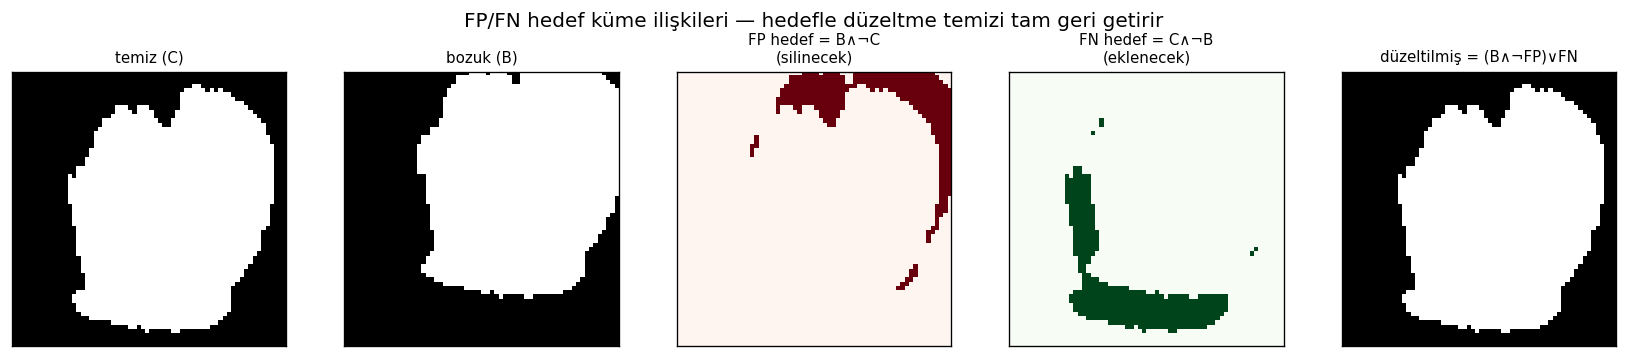

In [2]:
SEED = 42
config = load_config(str(PROJECT_ROOT / 'configs' / 'vae3d_imgcond_fpfn.yaml'))
config.setdefault('data', {})['data_source'] = 'precomputed'
set_seed(SEED)

ALL_FNS = {**PRIMITIVES_3D, **PARTIAL_PRIMITIVES_3D}
from data.degradations import dice as _dice

_clean_masks, _clean_images = evic.load_clean_image_volumes(config, 'test', None, SEED)
demo_clean = _clean_masks[0].astype(bool)
demo_img = _clean_images[0]
# orta siddette bir bozulma: hem silinecek hem eklenecek voksel olsun
demo_broken = np.asarray(ALL_FNS['translate'](demo_clean, 0.5, np.random.default_rng(SEED))) > 0

fp_t, fn_t = fpfn_targets(demo_broken[None].astype('float32'), demo_clean[None].astype('float32'))
fp_t, fn_t = fp_t[0] > 0.5, fn_t[0] > 0.5
recovered = correct_mask(demo_broken[None], fp_t[None], fn_t[None])[0] > 0.5
print('düzeltilmiş == temiz :', bool(np.array_equal(recovered, demo_clean)))
print('Dice(bozuk, temiz)   :', round(float(_dice(demo_clean, demo_broken)), 3))
print('|FP| =', int(fp_t.sum()), ' |FN| =', int(fn_t.sum()), ' |B XOR C| =',
      int((demo_broken ^ demo_clean).sum()))

zc = demo_clean.shape[0] // 2
panels = [('temiz (C)', demo_clean[zc], 'gray'), ('bozuk (B)', demo_broken[zc], 'gray'),
          ('FP hedef = B∧¬C\n(silinecek)', fp_t[zc], 'Reds'),
          ('FN hedef = C∧¬B\n(eklenecek)', fn_t[zc], 'Greens'),
          ('düzeltilmiş = (B∧¬FP)∨FN', recovered[zc], 'gray')]
fig, axes = plt.subplots(1, 5, figsize=(14, 3.0))
for ax, (t, v, cm) in zip(axes, panels):
    ax.imshow(v, cmap=cm); ax.set_title(t, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('FP/FN hedef küme ilişkileri — hedefle düzeltme temizi tam geri getirir', fontsize=12)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'rapor_fpfn_kume_iliskileri.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## 2b. Eğitimde FP/FN hedefleri nasıl üretildi? (collate boru hattı)

Bölüm 2 kavramı tek bir örnekte gösterir; burada **eğitim sırasında** her mini-batch için hedeflerin
tam olarak nasıl kurulduğu (`scripts/train_imgcond_fpfn.py` → `FPFNCollate`) özetlenir:

1. Her hasta için temiz maske `C` ve BT görüntüsü `I` yüklenir (temiz maske yalnızca **hedef kurmak**
   için; ağa asla girmez).
2. `C`, eğitim bozulma kümesiyle **rastgele** bozulur → `B` (varsayılan `mixed`: erode, dilate,
   remove_blob, add_false_positive, boundary_noise, translate; `partial` seçeneği saf tamamlama
   bozulmalarını kullanır). `make_pair(..., target_dice=None)` rastgele şiddet seçer, yani eğitimde
   girdi Dice'ı geniş bir aralıkta dağılır. **Girdi her zaman bozuktur** (FP/FN yalnızca bozuk bir
   girdiye göre anlamlıdır).
3. Hedefler **girdiye göreli** kurulur: `FP = B ∧ ¬C` (silinecek), `FN = C ∧ ¬B` (eklenecek).
4. Ağın **girdisi** `x = [I, B]` (2 kanal), **hedefi** `target = [FP, FN]` (2 kanal) olur.
5. Kayıp: ikili baş → FP ve FN için ayrı **BCE**; SDF-io baş → her bölgenin normalize SDF'si üzerinde
   **SmoothL1**. Toplam = `L(FP) + L(FN) + VQ`.

Aşağıdaki hücre bu collate mantığını birkaç **test** maskesinde birebir tekrarlar (eğitim kodundaki
`fpfn_targets` çağrısının aynısı) ve üretilen hedefleri gösterir — eğitimde modele verilen denetim
sinyalinin nasıl göründüğünü somutlaştırır.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_egitim_hedefleri.png


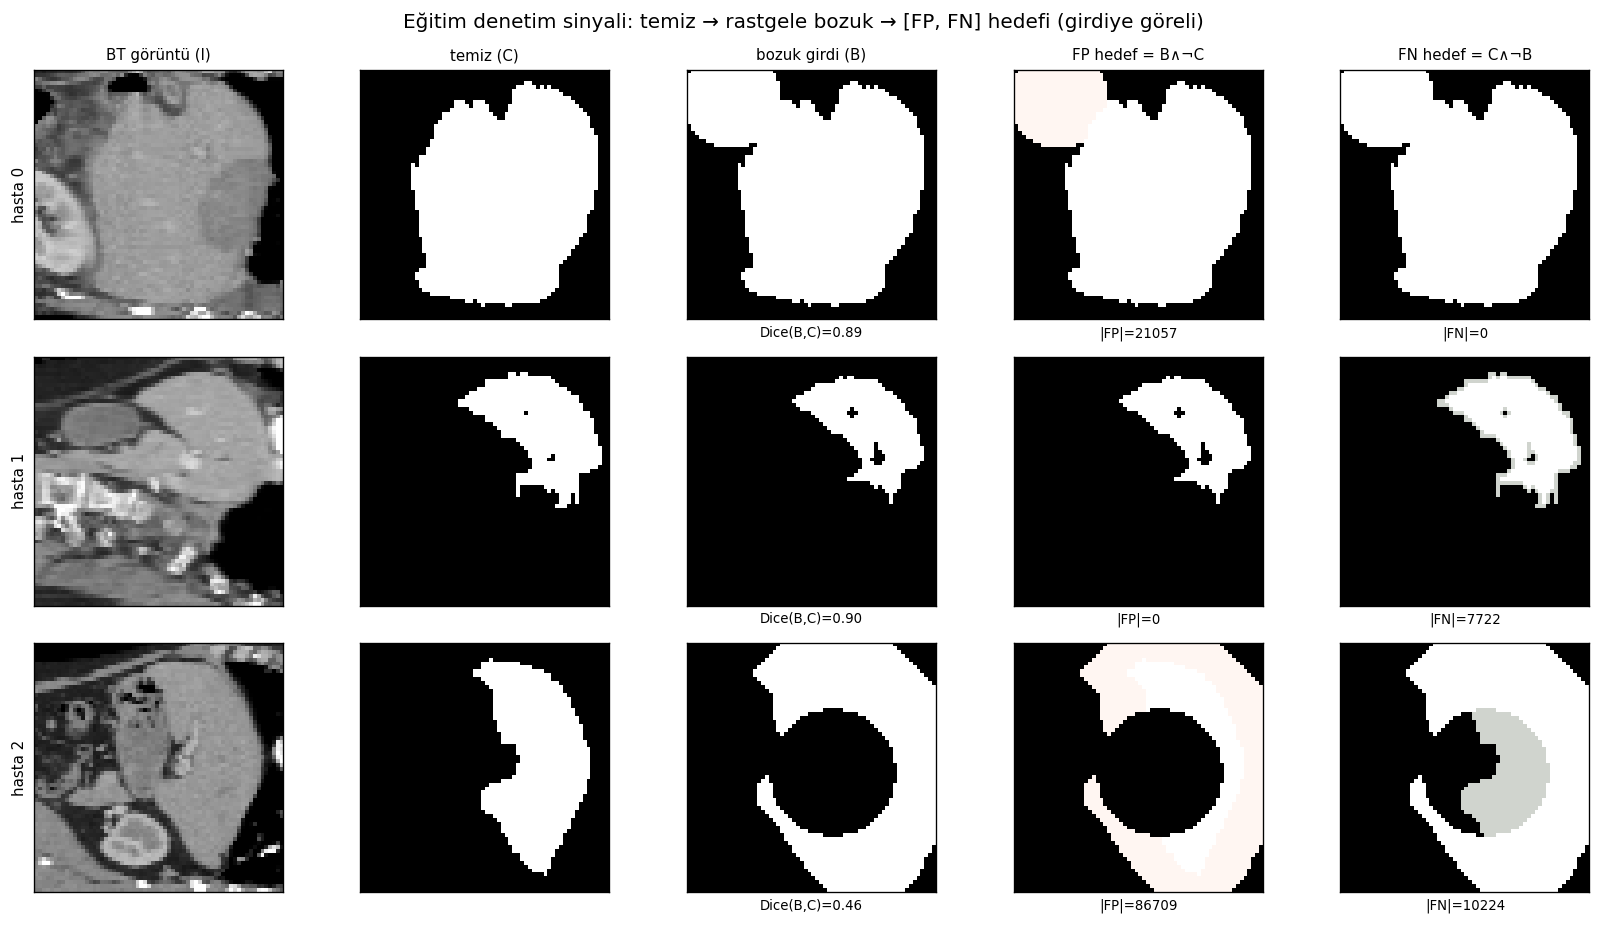

In [3]:
# Egitimdeki FPFNCollate ile AYNI hedef kurulumu (temiz -> rastgele bozuk -> FP/FN hedef).
train_degrader = ev3d.calibrate_degrader(config, _clean_masks, SEED)
rng_tr = np.random.default_rng(SEED)
n_demo = 3
fig, axes = plt.subplots(n_demo, 5, figsize=(14, 2.6 * n_demo))
cols = ['BT görüntü (I)', 'temiz (C)', 'bozuk girdi (B)', 'FP hedef = B∧¬C', 'FN hedef = C∧¬B']
for ri in range(n_demo):
    C = _clean_masks[ri].astype(bool); I = _clean_images[ri]
    degraded, d_in = train_degrader.make_pair(C, rng_tr, target_dice=None)  # egitimdeki cagrinin aynisi
    B = np.asarray(degraded) > 0
    fp, fn = fpfn_targets(B[None].astype('float32'), C[None].astype('float32'))
    fp, fn = fp[0] > 0.5, fn[0] > 0.5
    zc = C.shape[0] // 2
    axes[ri, 0].imshow(I[zc], cmap='gray')
    axes[ri, 1].imshow(C[zc], cmap='gray')
    axes[ri, 2].imshow(B[zc], cmap='gray')
    axes[ri, 3].imshow(B[zc], cmap='gray')
    axes[ri, 3].imshow(np.ma.masked_where(~fp[zc], fp[zc]), cmap='Reds', alpha=0.85)
    axes[ri, 4].imshow(B[zc], cmap='gray')
    axes[ri, 4].imshow(np.ma.masked_where(~fn[zc], fn[zc]), cmap='Greens', alpha=0.85)
    for ci in range(5):
        axes[ri, ci].set_xticks([]); axes[ri, ci].set_yticks([])
        if ri == 0: axes[ri, ci].set_title(cols[ci], fontsize=9)
    axes[ri, 0].set_ylabel(f'hasta {ri}', fontsize=9)
    axes[ri, 2].set_xlabel(f'Dice(B,C)={d_in:.2f}', fontsize=8)
    axes[ri, 3].set_xlabel(f'|FP|={int(fp.sum())}', fontsize=8)
    axes[ri, 4].set_xlabel(f'|FN|={int(fn.sum())}', fontsize=8)
fig.suptitle('Eğitim denetim sinyali: temiz → rastgele bozuk → [FP, FN] hedefi (girdiye göreli)', fontsize=12)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'rapor_fpfn_egitim_hedefleri.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## 3. Ortak değerlendirme kümesi (görüntü-farkında)

Test bölünmesindeki her temiz karaciğer için: standart bozulma primitifleri kalibre edilir, sonra her
temiz maskeden `N_PER_MASK` adet bozuk varyant üretilir. **Görüntü hastaya sabittir** — temiz ve bozuk
tüm satırlar aynı hastanın temiz BT görüntüsünü taşır. ASSD için her satır ayrıca temiz referans
maskeyi (`clean_ref`) taşır. Bütün FP/FN varyantları tam olarak bu kümede skorlanır.

In [4]:
N_PER_MASK = 5

clean_masks, clean_images = evic.load_clean_image_volumes(config, 'test', None, SEED)
degrader = ev3d.calibrate_degrader(config, clean_masks, SEED)
broken, images, clean_ref, true_dice, is_clean = evfpfn.build_eval_set_fpfn(
    clean_masks, clean_images, degrader, N_PER_MASK, SEED)
is_clean = np.asarray(is_clean, dtype=bool)
deg = ~is_clean

print(f'hasta sayısı (temiz karaciğer) : {len(clean_masks)}')
print(f'değerlendirme kümesi           : {len(broken)} hacim  ({is_clean.sum()} temiz + {deg.sum()} bozuk)')
print(f'her hacmin şekli (3B, 64³)     : {broken.shape[1:]}')
print(f'görüntü kanalı şekli           : {images.shape[1:]}  aralık [{images.min():.2f}, {images.max():.2f}]')
print(f'gerçek Dice aralığı            : [{true_dice.min():.3f}, {true_dice.max():.3f}]')
print(f'kalibre bozulma aralıkları     :')
for k, v in (degrader.type_ranges or {}).items():
    print(f'    {k:18s} Dice ∈ [{v[0]:.2f}, {v[1]:.2f}]')

hasta sayısı (temiz karaciğer) : 47
değerlendirme kümesi           : 282 hacim  (47 temiz + 235 bozuk)
her hacmin şekli (3B, 64³)     : (64, 64, 64)
görüntü kanalı şekli           : (64, 64, 64)  aralık [0.00, 1.00]
gerçek Dice aralığı            : [0.389, 1.000]
kalibre bozulma aralıkları     :
    erode              Dice ∈ [0.00, 0.94]
    dilate             Dice ∈ [0.42, 0.94]
    remove_blob        Dice ∈ [0.80, 1.00]
    add_false_positive Dice ∈ [0.86, 0.99]
    boundary_noise     Dice ∈ [0.49, 1.00]
    translate          Dice ∈ [0.19, 0.96]


## 4. Model kayıt defteri (4 varyant, eksikleri atlar)

Dört FP/FN deneyi: çıktı başı × nicemleyici. Girdi ve hedef mantığı tüm satırlarda **aynıdır**;
yalnızca iç gösterim (ikili maske vs işaretli-mesafe) ve nicemleyici (VQ vs SimVQ) değişir. Defter
checkpoint yollarından modelleri canlı yükler; henüz eğitilmemiş checkpoint'ler otomatik atlanır,
böylece defter bugün yalnızca mevcut olan(lar)la çalışır, kalanları eğitilince doldurur.

In [5]:
CKPT = PROJECT_ROOT / 'outputs' / 'checkpoints'

# (etiket, tag, head, quantizer)
FPFN_REGISTRY = [
    ('G-ikili/VQ',    'g_vq',          'binary', 'vq'),
    ('G-ikili/SimVQ', 'g_simvq',       'binary', 'simvq'),
    ('G-SDF/VQ',      'g_sdfio_vq',    'sdfio',  'vq'),
    ('G-SDF/SimVQ',   'g_sdfio_simvq', 'sdfio',  'simvq'),
]
for lbl, tag, *_ in FPFN_REGISTRY:
    p = CKPT / f'vae3d_{tag}_best.pt'
    print(('VAR ' if p.exists() else 'YOK ') + f'{lbl:16s} <- {p.name}')

VAR G-ikili/VQ       <- vae3d_g_vq_best.pt
VAR G-ikili/SimVQ    <- vae3d_g_simvq_best.pt
VAR G-SDF/VQ         <- vae3d_g_sdfio_vq_best.pt
VAR G-SDF/SimVQ      <- vae3d_g_sdfio_simvq_best.pt


## 5. FP/FN modellerini canlı skorla (GT-free skorlar + ASSD)

Her model checkpoint'ten yüklenir ve ortak değerlendirme kümesinde dört GT-free skor
(`est_dice`, `error_volume`, `fp_volume`, `fn_volume`) ile ASSD iyileşmesi (girdi → düzeltilmiş)
hesaplanır. Skorlar modelin tahmin ettiği FP/FN'den türetilir; rekonstrüksiyon yoktur.

In [6]:
fns, dirs = evfpfn.build_score_registry()
fpfn_results = {}   # etiket -> dict(scores, summary, assd, head, quantizer, epoch, model, path)

for lbl, tag, head, quant in FPFN_REGISTRY:
    path = CKPT / f'vae3d_{tag}_best.pt'
    if not path.exists():
        print('YOK, atlanıyor:', lbl); continue
    model = evfpfn.load_fpfn_model(path, head, quant, device)
    scores = evfpfn.score_masks_fpfn(model, broken, images, fns, device)
    summary = evfpfn.summarise(scores, true_dice, dirs)
    assd_stats = evfpfn.compute_assd_improvement(model, broken, images, clean_ref, is_clean, device)
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    fpfn_results[lbl] = dict(scores=scores, summary=summary, assd=assd_stats,
                             head=head, quantizer=quant, epoch=ckpt.get('epoch'),
                             model=model, path=str(path))
    ed = summary['est_dice']['global']['spearman']
    ev = summary['error_volume']['global']['spearman']
    print(f'{lbl:16s} [{head:6s}/{quant:5s}]  est_dice ρ={ed:+.3f}  error_volume ρ={ev:+.3f}  '
          f'ASSD {assd_stats["assd_input_mean"]:.2f}->{assd_stats["assd_corrected_mean"]:.2f}  '
          f'(epoch {ckpt.get("epoch")})')
if not fpfn_results:
    print('\\nHiç checkpoint bulunamadı — en az g_vq eğitilmiş olmalı.')

G-ikili/VQ       [binary/vq   ]  est_dice ρ=+0.948  error_volume ρ=-0.910  ASSD 3.24->1.87  (epoch 44)
G-ikili/SimVQ    [binary/simvq]  est_dice ρ=+0.956  error_volume ρ=-0.901  ASSD 3.24->1.71  (epoch 44)
G-SDF/VQ         [sdfio /vq   ]  est_dice ρ=+0.930  error_volume ρ=-0.899  ASSD 3.24->1.98  (epoch 42)
G-SDF/SimVQ      [sdfio /simvq]  est_dice ρ=+0.943  error_volume ρ=-0.897  ASSD 3.24->1.84  (epoch 44)


## 6. Özet tablo — GT-free skorların global ρ'su + ASSD

Her varyant için dört skorun global Spearman ρ'su ve ASSD (girdi → düzeltilmiş, sadece bozuk
satırlarda, nan atlanarak). `est_dice` birincil kalite skorudur; `error_volume` onun hacim-tabanlı
tümleyeni. ASSD azalması, FP/FN düzeltmesinin sınırı gerçek yüzeye yaklaştırdığını sayısal gösterir.

In [7]:
rows = []
for lbl, tag, head, quant in FPFN_REGISTRY:
    if lbl not in fpfn_results: continue
    r = fpfn_results[lbl]; s = r['summary']; a = r['assd']
    rows.append({
        'deney': lbl, 'baş': head, 'quant': quant,
        'ρ est_dice': round(float(s['est_dice']['global']['spearman']), 3),
        'ρ error_volume': round(float(s['error_volume']['global']['spearman']), 3),
        'ρ fp_volume': round(float(s['fp_volume']['global']['spearman']), 3),
        'ρ fn_volume': round(float(s['fn_volume']['global']['spearman']), 3),
        'ASSD girdi': round(float(a['assd_input_mean']), 3),
        'ASSD düzelt.': round(float(a['assd_corrected_mean']), 3),
        'ASSD azalma': round(float(a['assd_reduction']), 3),
    })
try:
    import pandas as pd
    summary_df = pd.DataFrame(rows)
    display(summary_df)
except Exception:
    for row in rows: print(row)

,deney,baş,quant,ρ est_dice,ρ error_volume,ρ fp_volume,ρ fn_volume,ASSD girdi,ASSD düzelt.,ASSD azalma
0,G-ikili/VQ,binary,vq,0.948,-0.910,-0.550,-0.596,3.243,1.870,1.373
1,G-ikili/SimVQ,binary,simvq,0.956,-0.901,-0.493,-0.614,3.243,1.710,1.533
2,G-SDF/VQ,sdfio,vq,0.930,-0.899,-0.519,-0.615,3.243,1.979,1.264
3,G-SDF/SimVQ,sdfio,simvq,0.943,-0.897,-0.537,-0.636,3.243,1.842,1.401


## 6b. GT-free Dice kestirim başarısı — tüm test görüntüleri

Defterin ana sorusu şudur: **ground-truth olmadan ürettiğimiz `est_dice`, gerçek Dice'ı ne kadar
doğru veriyor?** Bölüm 6 bunu sıralama (ρ) olarak özetliyordu; burada **doğrudan hata** olarak, tüm
test hacimleri (47 temiz + 235 bozuk = 282) üzerinden raporlanır:

- **MAE** = `ortalama |est_dice − gerçek Dice|` — kestirimin ortalama mutlak sapması (düşük = iyi).
- **RMSE** = karekök ortalama kare hata (büyük sapmaları cezalandırır).
- **≤0.05 / ≤0.10 oranı** = kestirimin gerçek Dice'a bu tolerans içinde düştüğü hacim yüzdesi
  (ör. "maskelerin %X'inde tahminimiz gerçeğin ±0.10'u içinde").
- **Pearson r / Spearman ρ** = doğrusal ve sıra-temelli korelasyon (tüm test).

Bu sayılar GT-free kalite skorunun **kestirim doğruluğunu** (sadece sıralamayı değil, mutlak değeri de)
tüm test üzerinde tek bakışta verir.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_estdice_basari.csv
kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_estdice_hata_dagilimi.png


,model,n,MAE,RMSE,≤0.05 oranı,≤0.10 oranı,Pearson r,Spearman ρ
0,G-ikili/VQ,282,0.0838,0.1060,0.362,0.606,0.936,0.948
1,G-ikili/SimVQ,282,0.0753,0.0970,0.404,0.638,0.941,0.956
2,G-SDF/VQ,282,0.1009,0.1293,0.344,0.525,0.901,0.930
3,G-SDF/SimVQ,282,0.0875,0.1129,0.372,0.560,0.913,0.943


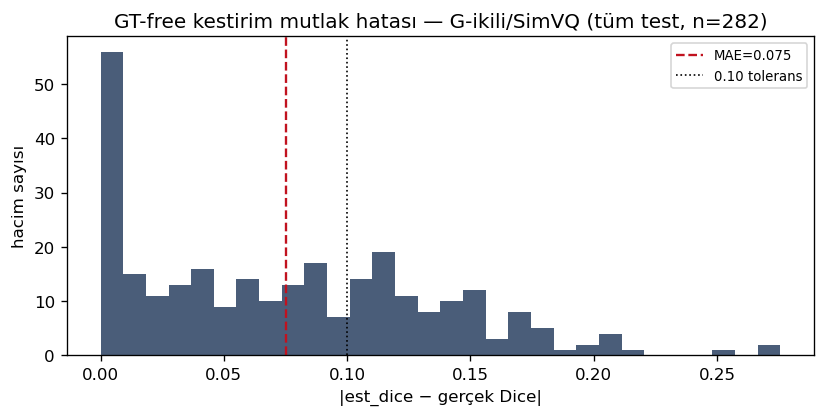

In [8]:
acc_rows = []
for lbl, tag, head, quant in FPFN_REGISTRY:
    if lbl not in fpfn_results: continue
    est = fpfn_results[lbl]['scores']['est_dice']
    err = np.abs(est - true_dice)
    c = correlation(est, true_dice)
    acc_rows.append({
        'model': lbl, 'n': int(len(true_dice)),
        'MAE': round(float(err.mean()), 4),
        'RMSE': round(float(np.sqrt((err ** 2).mean())), 4),
        '≤0.05 oranı': round(float((err <= 0.05).mean()), 3),
        '≤0.10 oranı': round(float((err <= 0.10).mean()), 3),
        'Pearson r': round(float(c['pearson']), 3),
        'Spearman ρ': round(float(c['spearman']), 3),
    })
try:
    import pandas as pd
    acc_df = pd.DataFrame(acc_rows)
    out_csv = PROJECT_ROOT / 'outputs' / 'rapor_fpfn_estdice_basari.csv'
    acc_df.to_csv(out_csv, index=False, encoding='utf-8'); print('kaydedildi:', out_csv)
    display(acc_df)
except Exception:
    for row in acc_rows: print(row)

# en iyi modelin |hata| dagilimi
labels = [l for l, *_ in FPFN_REGISTRY if l in fpfn_results]
if labels:
    best_lbl = max(labels, key=lambda l: fpfn_results[l]['summary']['est_dice']['global']['spearman'])
    est = fpfn_results[best_lbl]['scores']['est_dice']; err = np.abs(est - true_dice)
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.hist(err, bins=30, color='#1d3557', alpha=0.8)
    ax.axvline(err.mean(), color='#c1121f', ls='--', lw=1.4, label=f'MAE={err.mean():.3f}')
    ax.axvline(0.10, color='k', ls=':', lw=1, label='0.10 tolerans')
    ax.set_xlabel('|est_dice − gerçek Dice|'); ax.set_ylabel('hacim sayısı')
    ax.set_title(f'GT-free kestirim mutlak hatası — {best_lbl} (tüm test, n={len(err)})')
    ax.legend(fontsize=8); fig.tight_layout()
    out = PROJECT_ROOT / 'outputs' / 'rapor_fpfn_estdice_hata_dagilimi.png'
    fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## 7. Bant-içi (within-band) korelasyon — dürüst sayı

Global ρ tek başına yanıltıcıdır: 282 nokta yalnızca 47 hastadan gelir (her hasta 1 temiz + 5 bozuk),
dolayısıyla global Spearman ρ hastalar-arası varyansla **şişer** ve noktalar bağımsız olmadığından
p-değerleri aşırı iyimserdir. Bant-içi ρ, gerçek Dice'ı dar bantlara
(DICE_BANDS: [0.40–0.55], [0.55–0.70], [0.70–0.85], [0.85–1.0]) bölüp Spearman ρ'yu **her bandın
içinde** hesaplar — "birbirine yakın kalitedeki maskeleri bile skor doğru sıralayabiliyor mu?"
sorusunu yanıtlar. Aşağıda `est_dice` için bant-başına ρ tablosu ve çubuk grafik.

**En düşük bant [0.40–0.55] özellikle kritiktir**: en bozuk maskeler burada; bu bantta ρ düşükse
yöntem "en kötüler arasında" sıralama yapamıyor demektir. Bölüm 12'deki ağır-bozulma denemesi bu bandı
doğrudan hedefler.

In [9]:
def band_row(summary, score='est_dice'):
    return {f'[{b["band_lo"]:.2f}-{b["band_hi"]:.2f}] (n={b["n"]})': round(float(b['spearman']), 2)
            for b in summary[score]['bands']}

band_rows = []
for lbl, tag, head, quant in FPFN_REGISTRY:
    if lbl not in fpfn_results: continue
    s = fpfn_results[lbl]['summary']
    row = {'deney': lbl, 'global': round(float(s['est_dice']['global']['spearman']), 2)}
    row.update(band_row(s, 'est_dice'))
    band_rows.append(row)
try:
    import pandas as pd
    band_df = pd.DataFrame(band_rows)
    display(band_df)
except Exception:
    for row in band_rows: print(row)

,deney,global,[0.40-0.55] (n=59),[0.55-0.70] (n=56),[0.70-0.85] (n=58),[0.85-1.00] (n=108)
0,G-ikili/VQ,0.95,0.18,0.79,0.60,0.64
1,G-ikili/SimVQ,0.96,0.18,0.75,0.68,0.73
2,G-SDF/VQ,0.93,0.11,0.64,0.44,0.59
3,G-SDF/SimVQ,0.94,-0.03,0.64,0.68,0.70


kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_bant_ici_rho.png


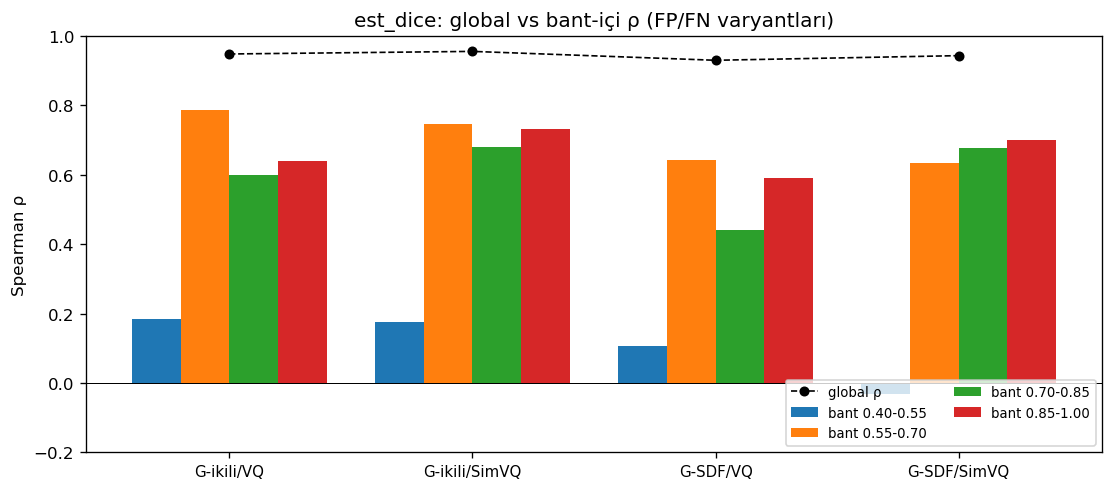

In [10]:
labels = [l for l, *_ in FPFN_REGISTRY if l in fpfn_results]
if labels:
    band_names = [f'{b["band_lo"]:.2f}-{b["band_hi"]:.2f}'
                  for b in fpfn_results[labels[0]]['summary']['est_dice']['bands']]
    nb_ = len(band_names)
    x = np.arange(len(labels)); w = 0.8 / nb_
    fig, ax = plt.subplots(figsize=(1.6 * len(labels) + 3, 4.2))
    for j, bn in enumerate(band_names):
        vals = [fpfn_results[l]['summary']['est_dice']['bands'][j]['spearman'] for l in labels]
        ax.bar(x + j * w, vals, w, label=f'bant {bn}')
    glob = [fpfn_results[l]['summary']['est_dice']['global']['spearman'] for l in labels]
    ax.plot(x + 0.4 - w/2, glob, 'ko--', lw=1, ms=5, label='global ρ')
    ax.set_xticks(x + 0.4 - w/2); ax.set_xticklabels(labels, fontsize=9)
    ax.set_ylabel('Spearman ρ'); ax.set_ylim(-0.2, 1.0)
    ax.axhline(0, color='k', lw=0.6)
    ax.set_title('est_dice: global vs bant-içi ρ (FP/FN varyantları)')
    ax.legend(fontsize=8, ncol=2, loc='lower right')
    fig.tight_layout()
    out = PROJECT_ROOT / 'outputs' / 'rapor_fpfn_bant_ici_rho.png'
    fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()
else:
    print('skorlanmış model yok.')

## 8. Scatter korelasyon grafikleri — est_dice vs gerçek Dice

Her varyantın `est_dice` skoru gerçek Dice'a karşı çizilir. Temiz (Dice=1.0) ve bozuk maskeler ayrı
renkli; dikey kesik çizgiler bant sınırları; başlıkta global ρ. İyi bir kestirici için noktalar
y=x köşegenine yakın dizilir (est_dice gerçek Dice'ı sadık kestirir).

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_scatter_hepsi.png


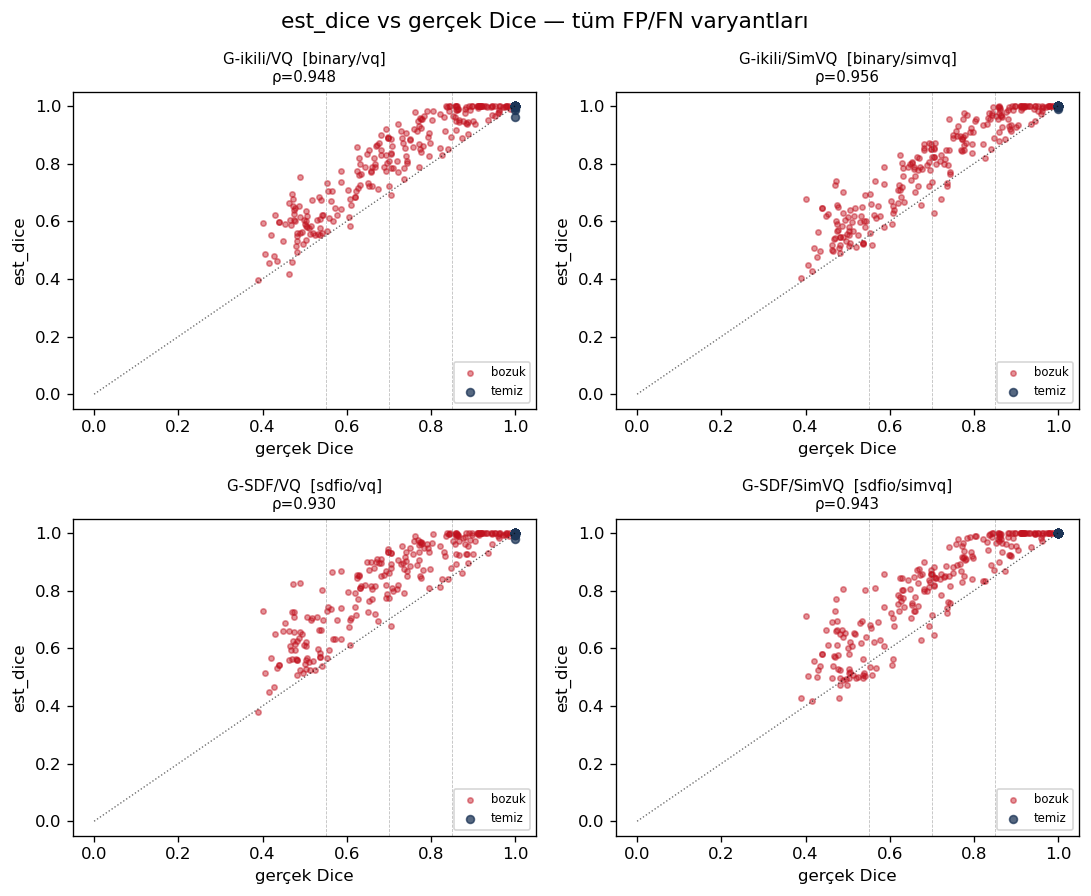

In [11]:
labels = [l for l, *_ in FPFN_REGISTRY if l in fpfn_results]
if labels:
    ncol = 2
    nrow = int(np.ceil(len(labels) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.8 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax, lbl in zip(axes, labels):
        r = fpfn_results[lbl]
        s = r['scores']['est_dice']
        rho = r['summary']['est_dice']['global']['spearman']
        ax.scatter(true_dice[deg], s[deg], s=10, alpha=0.45, c='#c1121f', label='bozuk')
        ax.scatter(true_dice[is_clean], s[is_clean], s=22, alpha=0.75, c='#1d3557', label='temiz')
        for _, hi in DICE_BANDS[:-1]:
            ax.axvline(hi, color='grey', lw=0.5, ls='--', alpha=0.5)
        ax.plot([0, 1], [0, 1], 'k:', lw=0.8, alpha=0.6)
        ax.set_title(f'{lbl}  [{r["head"]}/{r["quantizer"]}]\nρ={rho:.3f}', fontsize=9)
        ax.set_xlabel('gerçek Dice'); ax.set_ylabel('est_dice'); ax.legend(fontsize=7, loc='lower right')
    for ax in axes[len(labels):]:
        ax.axis('off')
    fig.suptitle('est_dice vs gerçek Dice — tüm FP/FN varyantları', fontsize=13)
    fig.tight_layout()
    out = PROJECT_ROOT / 'outputs' / 'rapor_fpfn_scatter_hepsi.png'
    fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()
else:
    print('skorlanmış model yok.')

## 9. Tek geniş tablo — her model × her hata türü (Dice + ASSD + Pearson/Spearman)

Bu tablo tek bakışta **hem model detayını hem bozulma-türü detayını** verir: 9 hata türünün her biri
için 4 varyantın başarımı, ana metrikler **Dice** ve **ASSD** üzerinden. Her satır bir *(hata türü,
model)* çiftidir; aynı tür için dört model alt alta gelir. Her tür için her hastaya o türün birkaç
şiddeti uygulanarak gerçek-Dice yelpazesi oluşturulur; `est_dice` ile gerçek Dice'ın tür-içi Pearson
ve Spearman korelasyonu son iki sütunda verilir.

### Sütunlar tam olarak ne anlama geliyor?

| Sütun | Tanım | Neyi gösterir |
|---|---|---|
| `hata türü` | Uygulanan bozulma primitifi | Hangi hata senaryosu (erozyon, kaydırma, kısmi, …) |
| `model` | Varyant (baş/nicemleyici) | Hangi FP/FN modeli |
| `n` | O tür+model için örnek sayısı | İstatistiğin dayandığı nokta sayısı |
| **`Dice girdi`** | Bozuk **girdi** maskesinin gerçek Dice'ı (GT ile), ortalama | Düzeltmeden **önce** maske kalitesi (düşük = daha bozuk girdi) |
| **`Dice düzelt`** | Modelin **düzelttiği** maskenin gerçek Dice'ı (GT ile), ortalama | Düzeltmeden **sonra** maske kalitesi. Yüksekse model FP/FN'yi doğru bulup maskeyi temize yaklaştırmış |
| `ΔDice` | `Dice düzelt − Dice girdi` | Düzeltmenin Dice kazancı (+ = iyileşme) |
| **`ASSD girdi`** | Bozuk **girdi** maskesi ile GT arasındaki ortalama simetrik yüzey mesafesi (voksel) | Düzeltmeden **önce** sınır/kenar hatası (yüksek = kötü) |
| **`ASSD düzelt`** | **Düzeltilmiş** maske ile GT arasındaki ASSD | Düzeltmeden **sonra** sınır hatası. Düşükse düzeltme sınırı gerçek yüzeye yaklaştırmış |
| `ΔASSD` | `ASSD girdi − ASSD düzelt` | ASSD azalması (+ = sınır iyileşti) |
| **`r est_dice`** | `est_dice` ile gerçek Dice'ın tür-içi **Pearson** katsayısı | GT-free skorun o tür içinde gerçek kaliteyi ne kadar doğrusal izlediği |
| **`ρ est_dice`** | Aynı ikilinin **Spearman** katsayısı | Sıra-temelli izleme (en kötü/en iyi sıralaması doğru mu) |

> **Önemli ayrım.** `Dice girdi`/`Dice düzelt`/`ASSD *` sütunları **düzeltilmiş maskenin** gerçek
> kalitesini ölçer (GT gerektirir, yalnızca doğrulama için). Asıl **ürün** ise son iki sütundur:
> `est_dice`'ın gerçek Dice ile korelasyonu — hastanede GT olmadan üretilen kalite skorunun güvenilirliği.
> Düzeltilmiş maske bir yan üründür; morfolojik olarak pürüzlü olsa bile `est_dice` korelasyonu yüksek
> kalabilir (ve asıl bakılması gereken budur).

In [12]:
from quality.surface_metrics import assd as _assd
from data.degradations import dice as _dc

# Her tur icin, gercek-Dice yelpazesi olusturacak birkac siddet (tur-ozel pencereler).
PER_TYPE_SEVS = {
    'erode':              [0.15, 0.30, 0.50],
    'dilate':             [0.20, 0.40, 0.60],
    'remove_blob':        [0.25, 0.45, 0.65],
    'add_false_positive': [0.25, 0.45, 0.65],
    'boundary_noise':     [0.35, 0.55, 0.75],
    'translate':          [0.20, 0.40, 0.60],
    'heavy_erode':        [0.20, 0.35, 0.50],
    'center_only':        [0.45, 0.60, 0.75],
    'partial':            [0.35, 0.55, 0.70],
}

def build_per_type_sets():
    sets = {}
    for name, sevs in PER_TYPE_SEVS.items():
        brk, imgs, refs, tds = [], [], [], []
        for pid, (gt, img) in enumerate(zip(clean_masks, clean_images)):
            gtb = gt.astype(bool)
            for sev in sevs:
                b = np.asarray(ALL_FNS[name](gtb, float(sev), np.random.default_rng(SEED + pid))) > 0
                if not (0 < int(b.sum()) < gtb.size):
                    continue
                brk.append(b); imgs.append(img); refs.append(gtb); tds.append(float(_dc(gtb, b)))
        sets[name] = (np.stack(brk), np.stack(imgs), np.stack(refs), np.asarray(tds))
    return sets

@torch.no_grad()
def eval_per_type(model, brk, imgs, refs, tds):
    est_all = []; dcorr = []; assd_in = []; assd_co = []
    for start in range(0, len(brk), 16):
        sl = slice(start, start + 16)
        m = brk[sl].astype('float32'); img = imgs[sl].astype('float32')
        x = torch.from_numpy(np.stack([img, m], 1)).to(device)
        fp, fn = model.predict_fpfn(x)
        est_all.append(estimated_dice(x[:, 1:2], fp, fn).cpu().numpy())
        corr = correct_mask(x[:, 1:2], fp, fn).cpu().numpy()[:, 0] > 0.5
        for j in range(m.shape[0]):
            gt = refs[start + j].astype(bool)
            dcorr.append(float(_dc(gt, corr[j])))
            assd_in.append(_assd(brk[start + j].astype(bool), gt))
            assd_co.append(_assd(corr[j], gt))
    est = np.concatenate(est_all)
    corr_stats = correlation(est, tds)
    return dict(est=est, dice_in=float(np.mean(tds)), dice_corr=float(np.mean(dcorr)),
                assd_in=float(np.nanmean(assd_in)), assd_corr=float(np.nanmean(assd_co)),
                pearson=float(corr_stats['pearson']), spearman=float(corr_stats['spearman']),
                n=int(len(tds)))

per_type_sets = build_per_type_sets()
print('tür başına örnek sayıları:', {k: int(len(v[3])) for k, v in per_type_sets.items()})

labels = [l for l, *_ in FPFN_REGISTRY if l in fpfn_results]
wide_rows = []
per_type_eval = {}   # (type, label) -> eval dict (scatter bölümü için saklanır)
for name in PER_TYPE_SEVS:
    brk, imgs, refs, tds = per_type_sets[name]
    for lbl in labels:
        r = eval_per_type(fpfn_results[lbl]['model'], brk, imgs, refs, tds)
        per_type_eval[(name, lbl)] = (tds, r['est'])
        wide_rows.append({
            'hata türü': name, 'model': lbl, 'n': r['n'],
            'Dice girdi': round(r['dice_in'], 3), 'Dice düzelt': round(r['dice_corr'], 3),
            'ΔDice': round(r['dice_corr'] - r['dice_in'], 3),
            'ASSD girdi': round(r['assd_in'], 2), 'ASSD düzelt': round(r['assd_corr'], 2),
            'ΔASSD': round(r['assd_in'] - r['assd_corr'], 2),
            'r est_dice': round(r['pearson'], 3), 'ρ est_dice': round(r['spearman'], 3),
        })

try:
    import pandas as pd
    wide_df = pd.DataFrame(wide_rows)
    out_csv = PROJECT_ROOT / 'outputs' / 'rapor_fpfn_genis_tablo.csv'
    wide_df.to_csv(out_csv, index=False, encoding='utf-8')
    print('kaydedildi:', out_csv)
    display(wide_df)
except Exception as exc:
    print('pandas yok, ham satırlar:', exc)
    for row in wide_rows: print(row)

tür başına örnek sayıları: {'erode': 141, 'dilate': 141, 'remove_blob': 141, 'add_false_positive': 141, 'boundary_noise': 141, 'translate': 141, 'heavy_erode': 77, 'center_only': 141, 'partial': 141}
kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_genis_tablo.csv


,hata türü,model,n,Dice girdi,Dice düzelt,ΔDice,ASSD girdi,ASSD düzelt,ΔASSD,r est_dice,ρ est_dice
0,erode,G-ikili/VQ,141,0.606,0.814,0.208,3.80,1.69,2.11,0.986,0.970
1,erode,G-ikili/SimVQ,141,0.606,0.814,0.208,3.80,1.71,2.09,0.981,0.969
2,erode,G-SDF/VQ,141,0.606,0.791,0.185,3.80,1.90,1.89,0.976,0.969
3,erode,G-SDF/SimVQ,141,0.606,0.797,0.192,3.80,1.87,1.92,0.979,0.966
4,dilate,G-ikili/VQ,141,0.715,0.777,0.061,3.68,2.12,1.56,0.951,0.856
5,dilate,G-ikili/SimVQ,141,0.715,0.819,0.104,3.68,1.82,1.86,0.937,0.824
6,dilate,G-SDF/VQ,141,0.715,0.772,0.057,3.68,2.20,1.48,0.923,0.816
7,dilate,G-SDF/SimVQ,141,0.715,0.795,0.079,3.68,2.05,1.63,0.955,0.864
8,remove_blob,G-ikili/VQ,141,0.934,0.968,0.033,0.40,0.39,0.00,0.926,0.913
9,remove_blob,G-ikili/SimVQ,141,0.934,0.970,0.036,0.40,0.37,0.03,0.928,0.906


## 10. Hata türüne göre renklendirilmiş scatter — est_dice vs gerçek Dice (Pearson)

Bölüm 8'deki scatter tüm bozulmaları tek renkte topluyordu; burada **her nokta hata türüne göre
renklendirilir**, böylece hangi türde `est_dice`'ın gerçek Dice'ı iyi/kötü izlediği görülür. Her
alt-grafik bir modeldir; başlıkta o modelin tüm türler üzerindeki genel **Pearson r** değeri yazar.
Köşegen (y=x) ideal kestiriciyi temsil eder.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_scatter_turlere_gore.png


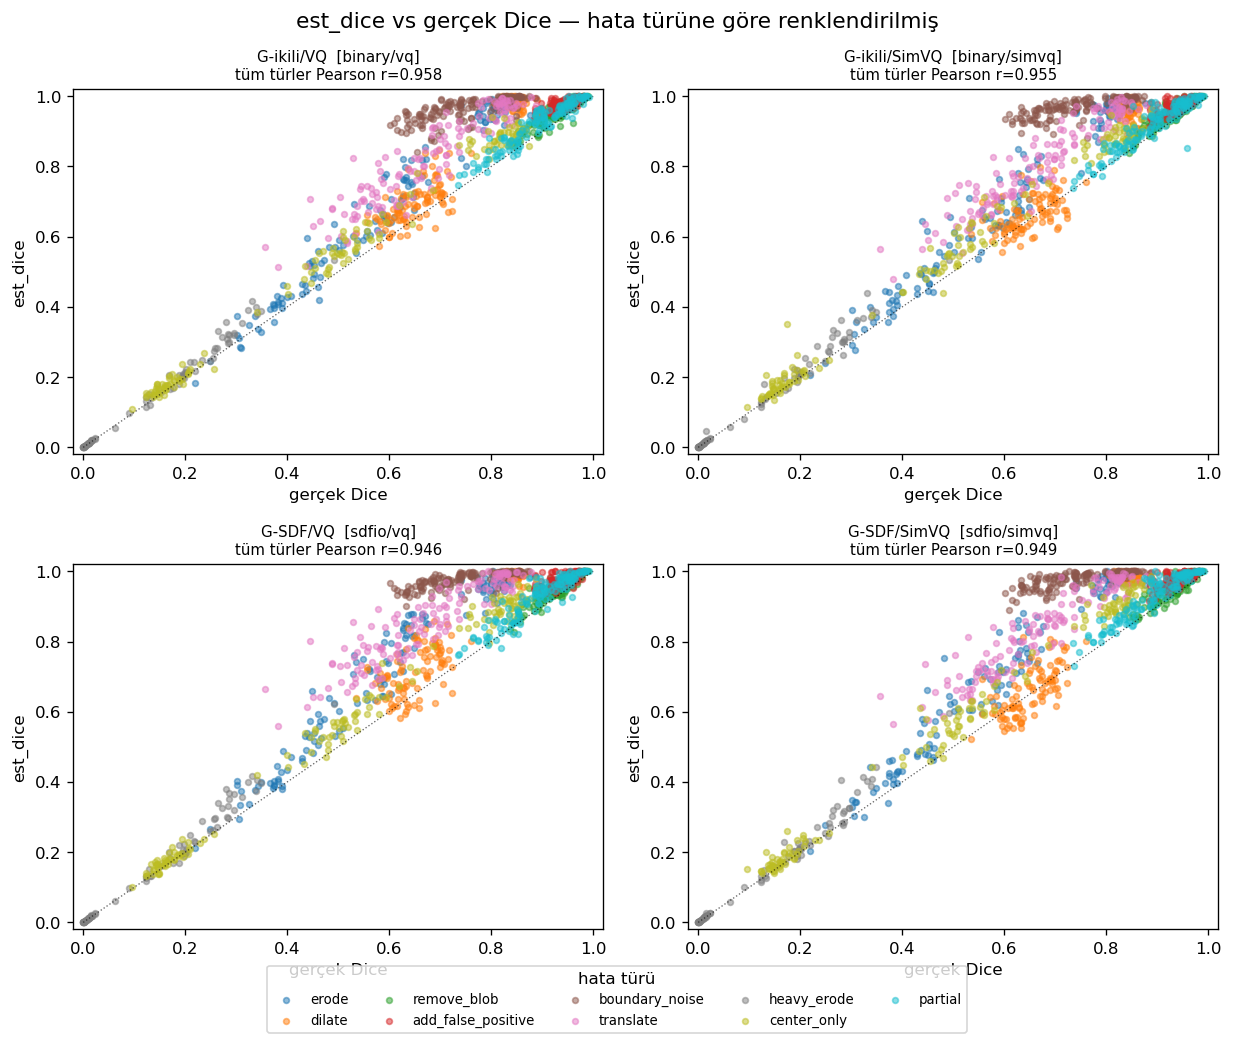

In [13]:
import matplotlib.cm as cm

labels = [l for l, *_ in FPFN_REGISTRY if l in fpfn_results]
if labels and per_type_eval:
    type_names = list(PER_TYPE_SEVS)
    palette = cm.get_cmap('tab10', len(type_names))
    ncol = 2
    nrow = int(np.ceil(len(labels) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 4.2 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax, lbl in zip(axes, labels):
        all_td, all_es = [], []
        for ti, name in enumerate(type_names):
            if (name, lbl) not in per_type_eval:
                continue
            td, es = per_type_eval[(name, lbl)]
            all_td.append(td); all_es.append(es)
            ax.scatter(td, es, s=12, alpha=0.5, color=palette(ti), label=name)
        td_all = np.concatenate(all_td); es_all = np.concatenate(all_es)
        r_all = correlation(es_all, td_all)['pearson']
        ax.plot([0, 1], [0, 1], 'k:', lw=0.8, alpha=0.6)
        ax.set_title(f'{lbl}  [{fpfn_results[lbl]["head"]}/{fpfn_results[lbl]["quantizer"]}]\n'
                     f'tüm türler Pearson r={r_all:.3f}', fontsize=9)
        ax.set_xlabel('gerçek Dice'); ax.set_ylabel('est_dice')
        ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    for ax in axes[len(labels):]:
        ax.axis('off')
    handles, lbls_ = axes[0].get_legend_handles_labels()
    fig.legend(handles, lbls_, loc='lower center', ncol=5, fontsize=8,
               bbox_to_anchor=(0.5, -0.04), title='hata türü')
    fig.suptitle('est_dice vs gerçek Dice — hata türüne göre renklendirilmiş', fontsize=13)
    fig.tight_layout()
    out = PROJECT_ROOT / 'outputs' / 'rapor_fpfn_scatter_turlere_gore.png'
    fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()
else:
    print('skorlanmış model yok.')

## 11. FP/FN haritaları — tahmin edilen silme/ekleme, hafif → ağır bozulma

Her varyant **aynı hastada** ve **aynı üç bozuk girdide** (hafif, orta, ağır) gösterilir. Sütunlar:

**BT görüntü | temiz (GT) | bozuk girdi | tahmini FP (kırmızı=sil) | tahmini FN (yeşil=ekle) | düzeltilmiş maske**

Tahmini FP/FN, modelin girdi maskesindeki fazlalık/eksik bölgeleri nasıl işaretlediğini gösterir;
düzeltilmiş maske `(B ∧ ¬FP) ∨ FN`'dir. **Bozuk girdi** sütununun altında iki sayı yazar:
`Dice(girdi,GT)` (girdinin gerçek kalitesi, doğrulama için) ve **`est_dice`** (modelin GT'siz tahmin
ettiği kalite — asıl ürün). Son sütunda düzeltilmiş maskenin gerçek Dice'ı (yan ürün) verilir. Yani
**tahmini Dice'ı (est_dice) bozuk girdi sütununun altında** görürsünüz.

panel bozuk girdiler (seviye, primitif, Dice): [('hafif/partial', 0.86), ('orta/erode', 0.62), ('ağır/center_only', 0.34)]
kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_panel_G-ikili_VQ.png
kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_panel_G-ikili_SimVQ.png
kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_panel_G-SDF_VQ.png
kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_panel_G-SDF_SimVQ.png


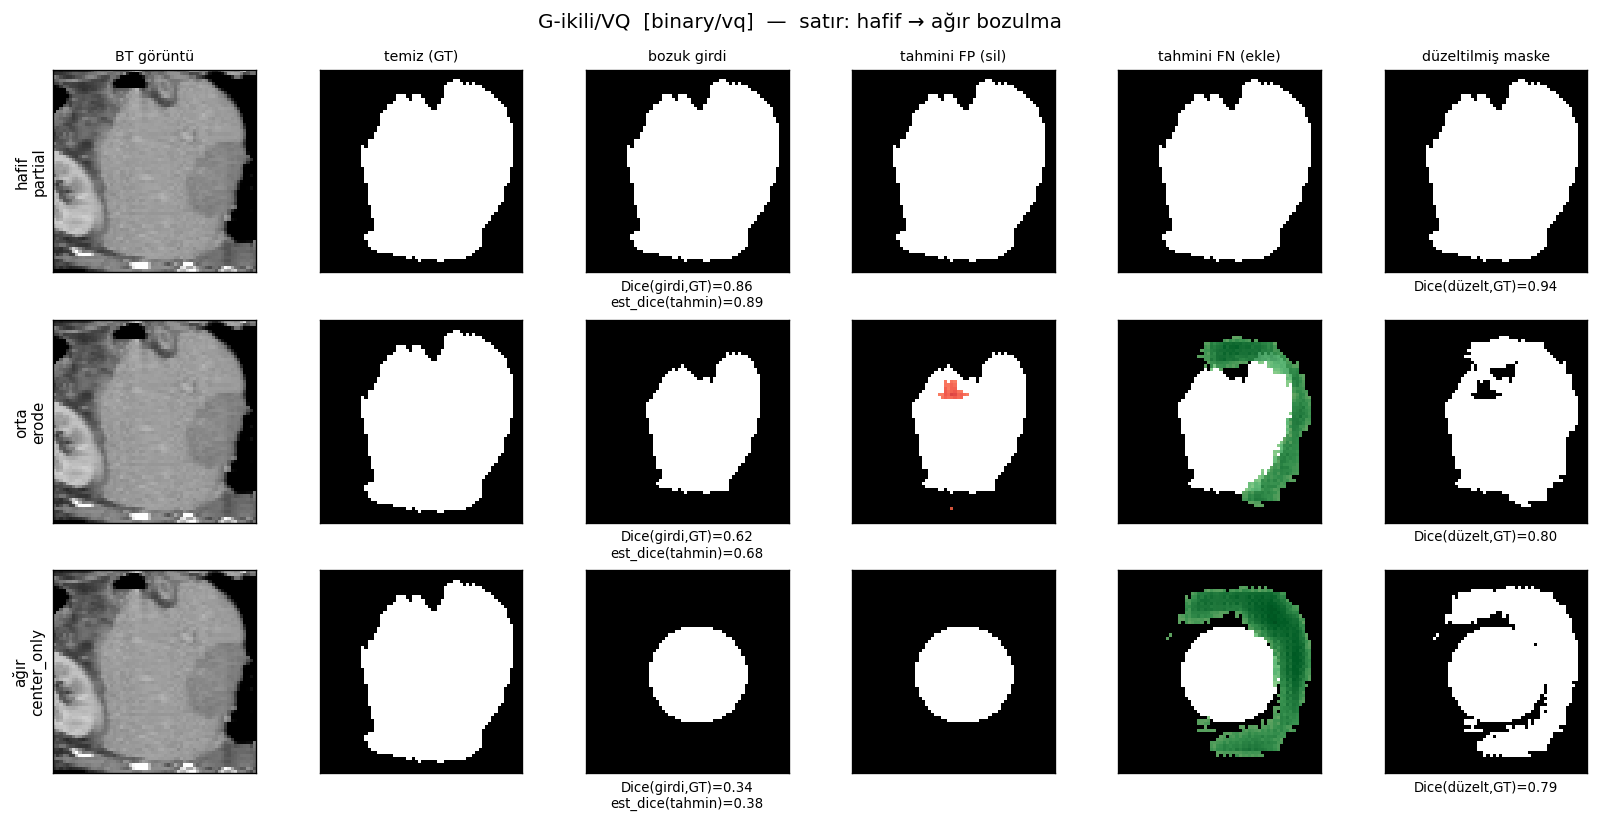

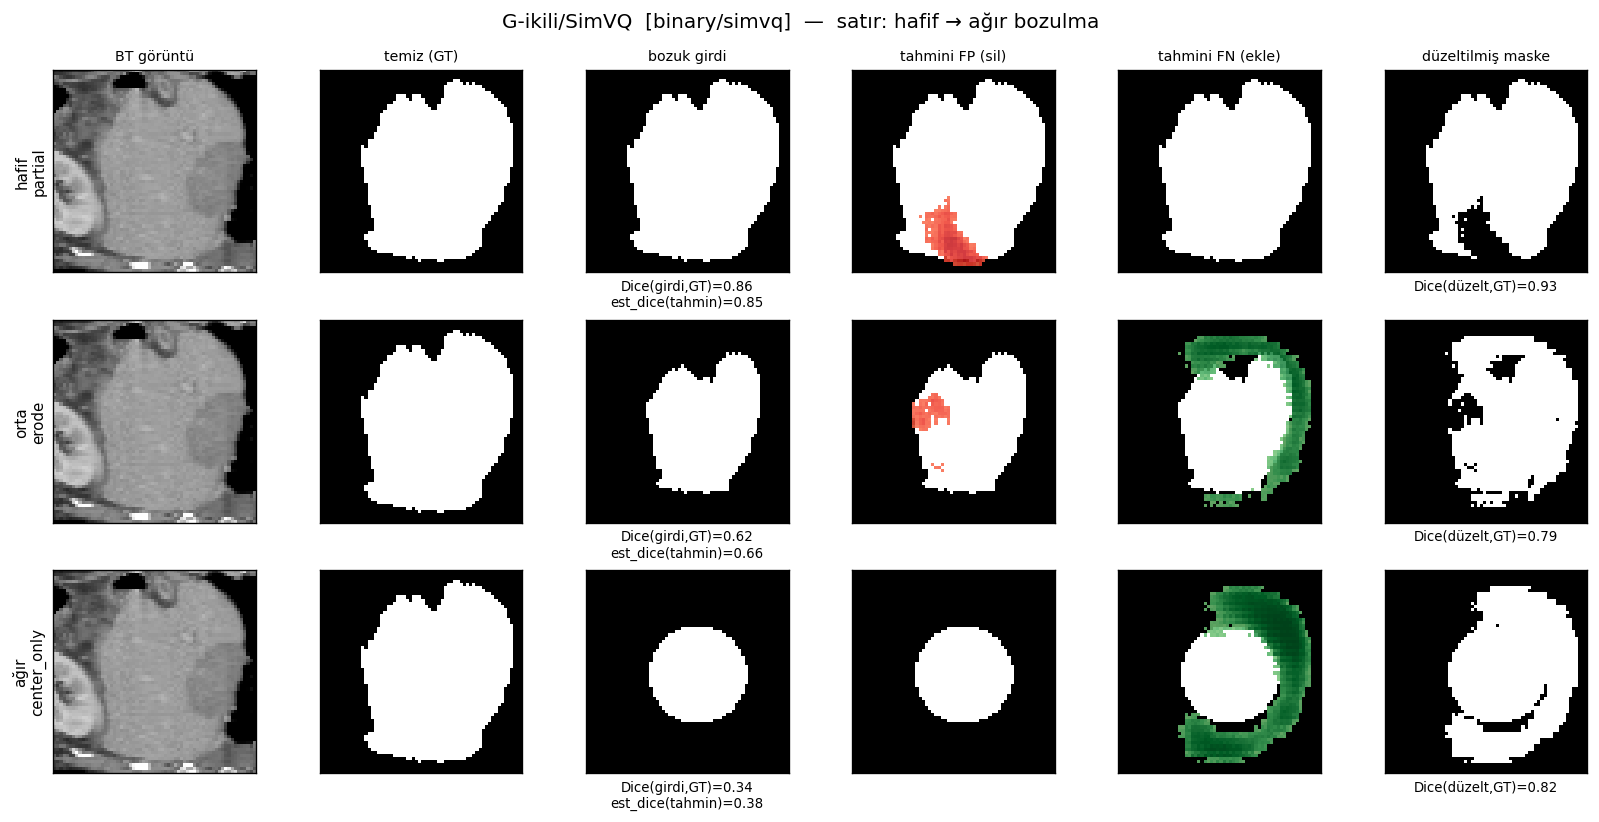

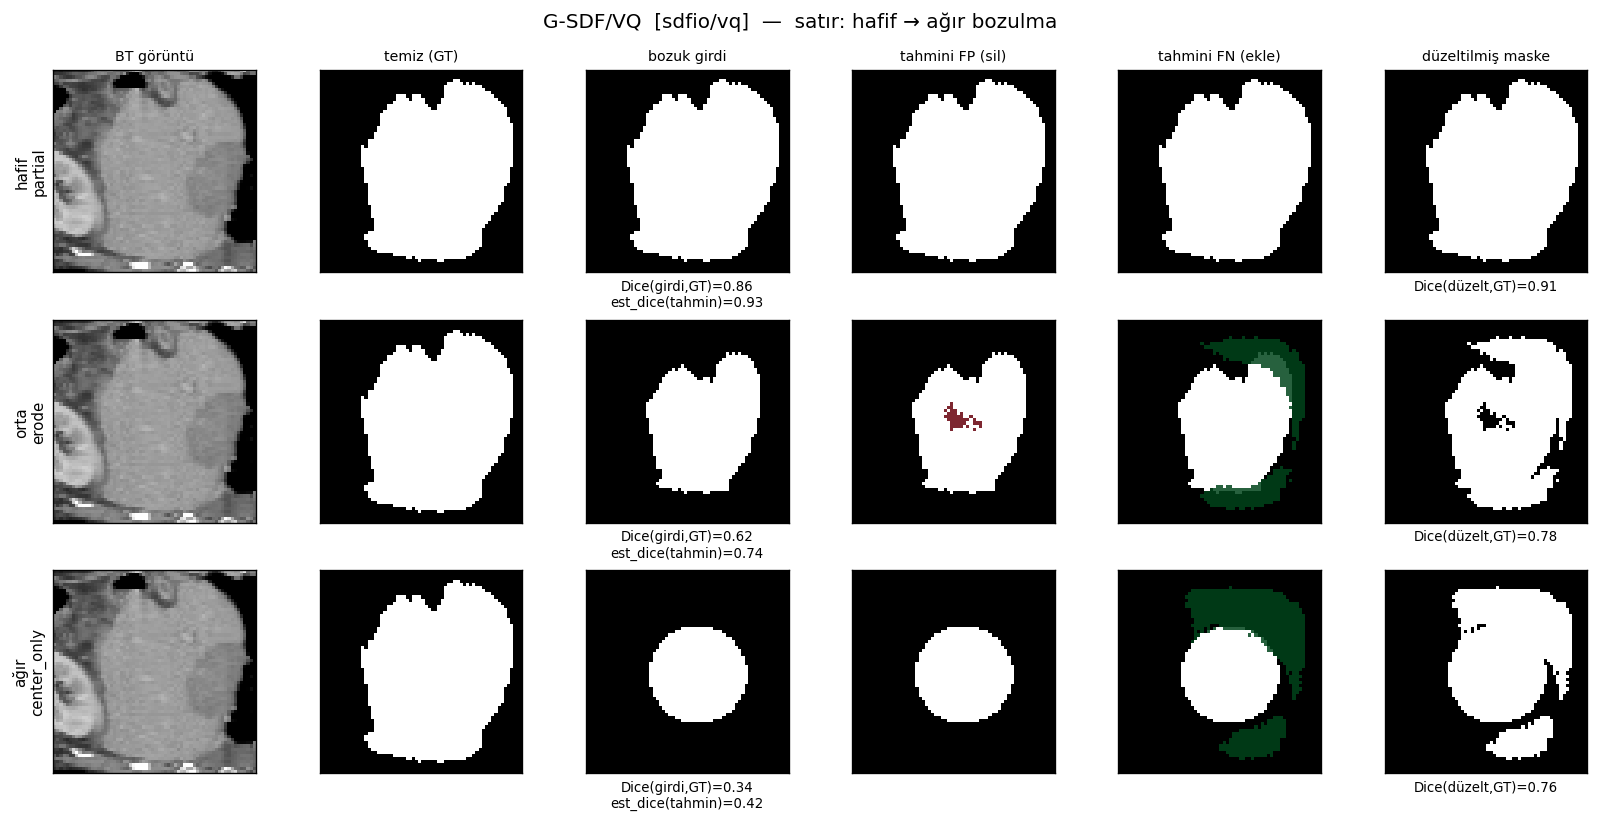

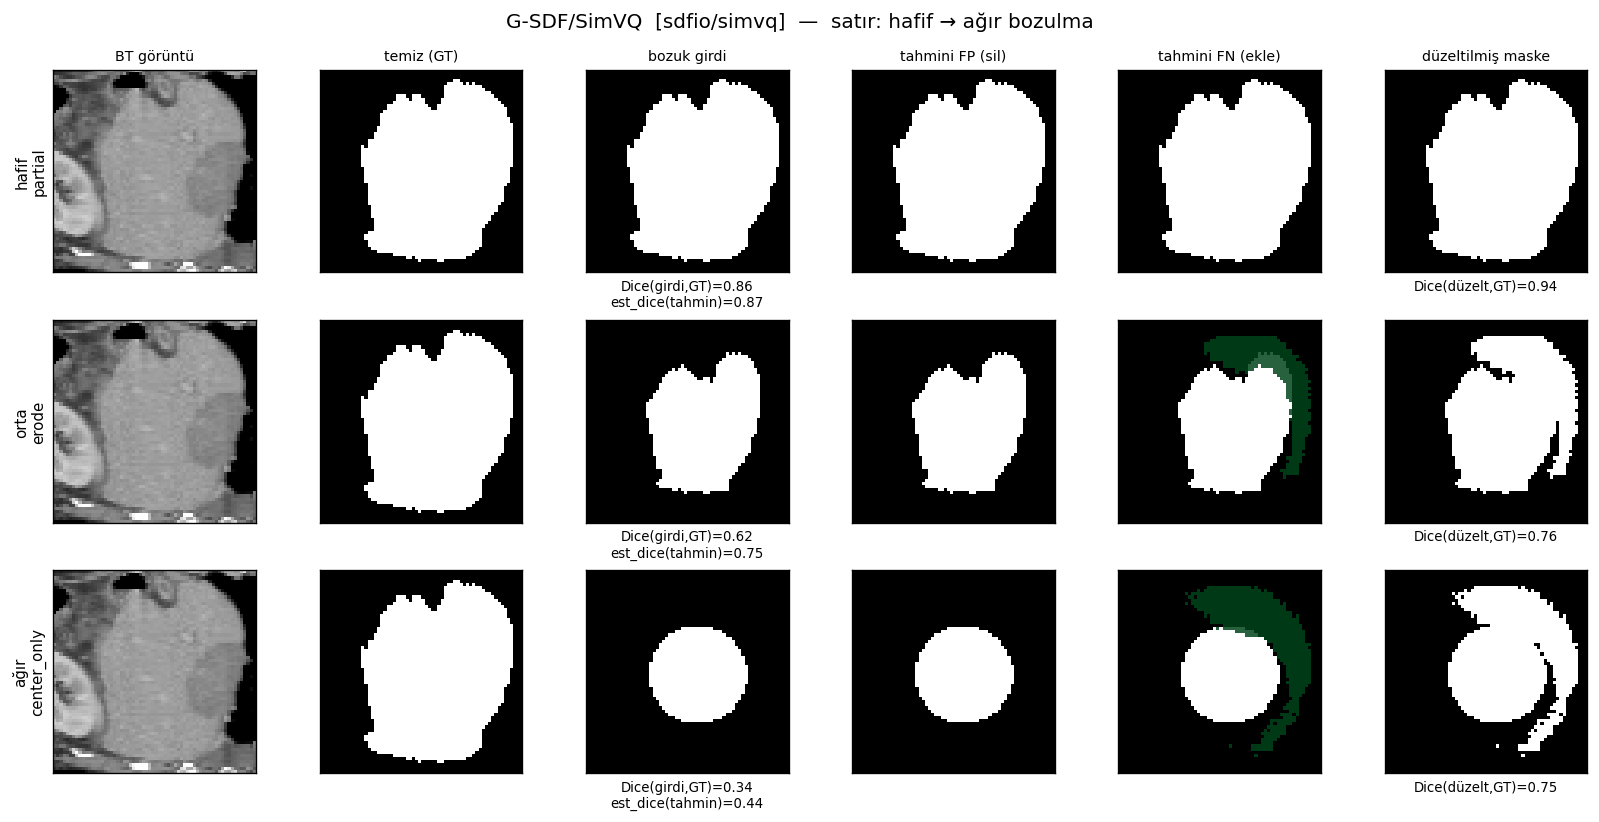

In [14]:
from data.degradations import dice as _dc

PANEL_IDX = 0
panel_gt = clean_masks[PANEL_IDX].astype(bool)
panel_img = clean_images[PANEL_IDX]
_cands = []
for name, sev in [('erode', 0.15), ('erode', 0.3), ('erode', 0.5), ('dilate', 0.4),
                  ('partial', 0.4), ('partial', 0.6), ('heavy_erode', 0.3),
                  ('center_only', 0.4), ('center_only', 0.6), ('center_only', 0.75)]:
    b = np.asarray(ALL_FNS[name](panel_gt, sev, np.random.default_rng(SEED))) > 0
    if 0 < int(b.sum()) < panel_gt.size:
        _cands.append((b, float(_dc(panel_gt, b)), name))
panel_broken = []
_used = []
for target, lvl in [(0.85, 'hafif'), (0.65, 'orta'), (0.45, 'ağır')]:
    best_k = min((k for k in range(len(_cands)) if k not in _used),
                 key=lambda k: abs(_cands[k][1] - target))
    _used.append(best_k)
    b, d, name = _cands[best_k]
    panel_broken.append((b, d, f'{lvl}\n{name}'))
zc = panel_gt.shape[0] // 2
print('panel bozuk girdiler (seviye, primitif, Dice):',
      [(lvl.replace(chr(10), '/'), round(d, 2)) for _, d, lvl in panel_broken])

@torch.no_grad()
def predict_maps(model, img, mask):
    x = torch.from_numpy(np.stack([img, mask.astype('float32')])[None]).float().to(device)
    fp, fn = model.predict_fpfn(x)
    corr = correct_mask(x[:, 1:2], fp, fn)
    return (fp[0, 0].cpu().numpy(), fn[0, 0].cpu().numpy(), corr[0, 0].cpu().numpy() > 0.5)

def fpfn_panel(lbl):
    r = fpfn_results[lbl]; model = r['model']
    cols = ['BT görüntü', 'temiz (GT)', 'bozuk girdi', 'tahmini FP (sil)',
            'tahmini FN (ekle)', 'düzeltilmiş maske']
    fig, axes = plt.subplots(len(panel_broken), len(cols),
                             figsize=(2.3 * len(cols), 2.3 * len(panel_broken)))
    for ri, (brk, d_in, lvl) in enumerate(panel_broken):
        fp, fn, comp = predict_maps(model, panel_img, brk)
        d_comp = float(_dc(panel_gt, comp))
        x_ = torch.from_numpy(np.stack([panel_img, brk.astype('float32')])[None]).float().to(device)
        with torch.no_grad():
            _fp, _fn = model.predict_fpfn(x_)
            ed = float(estimated_dice(x_[:, 1:2], _fp, _fn)[0])   # tahmini (GT-free) Dice
        axes[ri, 0].imshow(panel_img[zc], cmap='gray')
        axes[ri, 1].imshow(panel_gt[zc], cmap='gray')
        axes[ri, 2].imshow(brk[zc], cmap='gray')
        axes[ri, 3].imshow(brk[zc], cmap='gray')
        axes[ri, 3].imshow(np.ma.masked_where(fp[zc] <= 0.5, fp[zc]), cmap='Reds', vmin=0, vmax=1, alpha=0.85)
        axes[ri, 4].imshow(brk[zc], cmap='gray')
        axes[ri, 4].imshow(np.ma.masked_where(fn[zc] <= 0.5, fn[zc]), cmap='Greens', vmin=0, vmax=1, alpha=0.85)
        axes[ri, 5].imshow(comp[zc], cmap='gray')
        for ci in range(len(cols)):
            axes[ri, ci].set_xticks([]); axes[ri, ci].set_yticks([])
            if ri == 0:
                axes[ri, ci].set_title(cols[ci], fontsize=8.5)
        axes[ri, 0].set_ylabel(lvl, fontsize=9)
        axes[ri, 2].set_xlabel(f'Dice(girdi,GT)={d_in:.2f}\nest_dice(tahmin)={ed:.2f}', fontsize=8)
        axes[ri, 5].set_xlabel(f'Dice(düzelt,GT)={d_comp:.2f}', fontsize=8)
    fig.suptitle(f'{lbl}  [{r["head"]}/{r["quantizer"]}]  —  satır: hafif → ağır bozulma',
                 fontsize=12)
    fig.tight_layout()
    out = PROJECT_ROOT / 'outputs' / f'rapor_fpfn_panel_{lbl.replace("/", "_")}.png'
    fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

for lbl, *_ in FPFN_REGISTRY:
    if lbl in fpfn_results:
        fpfn_panel(lbl)

## 11b. Tek hastada TÜM modeller — TEK BAŞINA çalışan hücre (yalnızca `PATIENT_IDX` değiştir)

Bu hücre **tamamen bağımsızdır**: tüm import'ları, config/veri yüklemeyi, degrader kalibrasyonunu ve
4 modelin yüklenmesini kendi içinde yapar; başka hiçbir hücreyi çalıştırmanıza gerek yoktur. İlk
çalıştırmada kurulum yapılır ve belleğe alınır (cache); sonrasında sadece `PATIENT_IDX` (veya
`TARGET_DICE`) değiştirip hücreyi **tekrar çalıştırmak** saniyeler sürer — ağır kurulum yeniden
yapılmaz. **Aynı bozuk girdi** tüm modellere verilir (adil karşılaştırma). Çıktı: görsel panel
(satır = model) + tablolu sonuçlar (est_dice=tahmini Dice, gerçek/düzeltilmiş Dice, hata hacimleri, ASSD).

yüklendi: G-ikili/VQ
yüklendi: G-ikili/SimVQ
yüklendi: G-SDF/VQ
yüklendi: G-SDF/SimVQ
kurulum tamam (cache alındı). Artık sadece PATIENT_IDX değiştirip tekrar çalıştır.
kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_tum_modeller_hasta0.png


,model,Dice girdi (GT),est_dice (tahmini Dice),Dice düzelt (GT),error_volume,fp_volume,fn_volume,ASSD girdi,ASSD düzelt
0,G-ikili/VQ,0.621,0.685,0.796,38511,315,38196,5.1,2.53
1,G-ikili/SimVQ,0.621,0.663,0.793,40904,506,40398,5.1,2.64
2,G-SDF/VQ,0.621,0.742,0.775,30789,97,30692,5.1,2.75
3,G-SDF/SimVQ,0.621,0.754,0.757,26626,0,26626,5.1,2.74


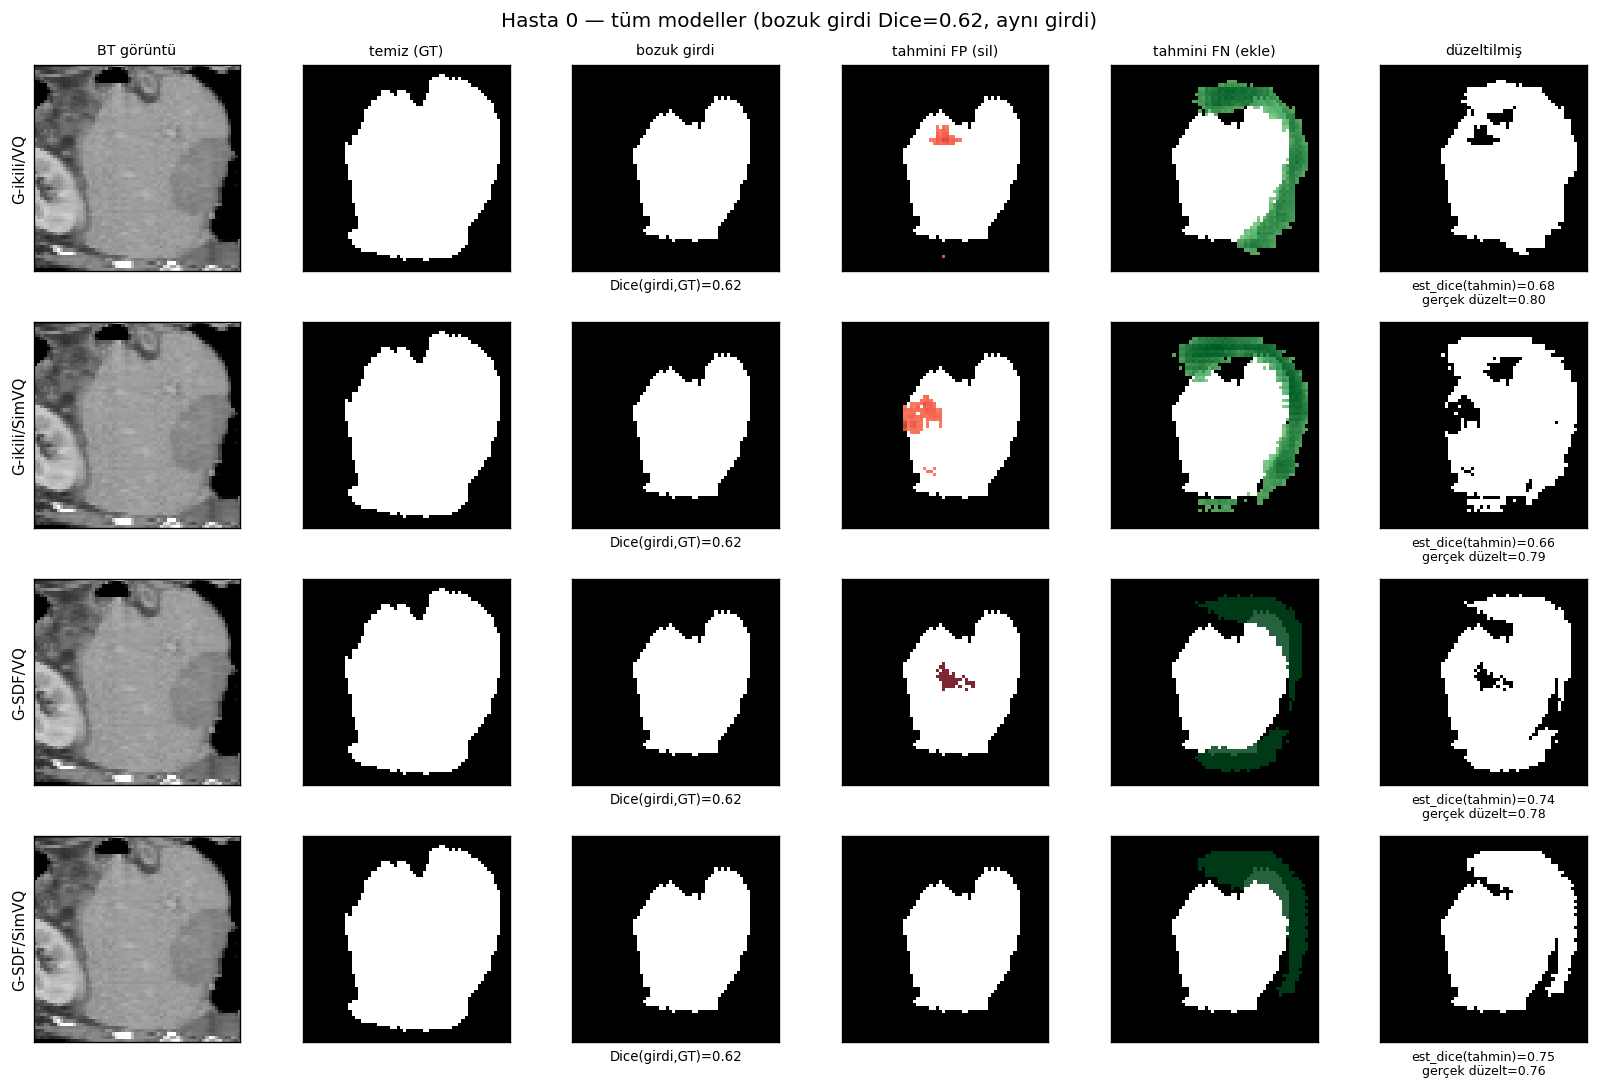

In [15]:
# ================== TEK BAŞINA ÇALIŞAN HÜCRE — sadece bunu çalıştır ==================
PATIENT_IDX = 0       # <-- yalnizca burayi (ve istersen TARGET_DICE'i) degistir
TARGET_DICE = 0.6     # bozuk girdinin hedef Dice'i (aynisi tum modellere verilir)

# -- kurulum (yalnizca ilk calistirmada; sonra cache'ten gelir) ----------------------
if '_SA' not in globals():
    import sys as _sys
    from pathlib import Path as _Path
    import numpy as _np, torch as _torch
    import matplotlib.pyplot as _plt

    def _find_root(start):
        p = _Path(start).resolve()
        for c in [p, *p.parents]:
            if (c / 'scripts').is_dir() and (c / 'models').is_dir():
                return c
        return p
    _ROOT = _find_root(_Path.cwd())
    for _p in (_ROOT, _ROOT / 'scripts'):
        if str(_p) not in _sys.path:
            _sys.path.insert(0, str(_p))

    from data import load_config as _load_config
    from data.fpfn_targets import correct_mask as _correct_mask, estimated_dice as _estimated_dice, \
        error_volume as _error_volume
    from data.degradations import dice as _dc_sa
    from quality.surface_metrics import assd as _assd_sa
    from train import resolve_device as _resolve_device, set_seed as _set_seed
    import evaluate_correlation_3d as _ev3d
    import evaluate_correlation_imgcond as _evic
    import evaluate_correlation_imgcond_fpfn as _evf

    _SEED = 42
    _cfg = _load_config(str(_ROOT / 'configs' / 'vae3d_imgcond_fpfn.yaml'))
    _cfg.setdefault('data', {})['data_source'] = 'precomputed'
    _set_seed(_SEED)
    _dev = _resolve_device('auto')
    _cm, _ci = _evic.load_clean_image_volumes(_cfg, 'test', None, _SEED)
    _deg = _ev3d.calibrate_degrader(_cfg, _cm, _SEED)

    _REG = [('G-ikili/VQ', 'g_vq', 'binary', 'vq'), ('G-ikili/SimVQ', 'g_simvq', 'binary', 'simvq'),
            ('G-SDF/VQ', 'g_sdfio_vq', 'sdfio', 'vq'), ('G-SDF/SimVQ', 'g_sdfio_simvq', 'sdfio', 'simvq')]
    _CK = _ROOT / 'outputs' / 'checkpoints'
    _models = {}
    for _lbl, _tag, _h, _q in _REG:
        _pth = _CK / f'vae3d_{_tag}_best.pt'
        if _pth.exists():
            _models[_lbl] = _evf.load_fpfn_model(_pth, _h, _q, _dev)
            print('yüklendi:', _lbl)
        else:
            print('YOK, atlanıyor:', _lbl)
    _SA = dict(ROOT=_ROOT, np=_np, torch=_torch, plt=_plt, dev=_dev, SEED=_SEED,
               cm=_cm, ci=_ci, deg=_deg, models=_models,
               correct_mask=_correct_mask, estimated_dice=_estimated_dice,
               error_volume=_error_volume, dc=_dc_sa, assd=_assd_sa)
    print('kurulum tamam (cache alındı). Artık sadece PATIENT_IDX değiştirip tekrar çalıştır.')

# -- her calistirmada (hizli) --------------------------------------------------------
_np = _SA['np']; _torch = _SA['torch']; _plt = _SA['plt']; _dev = _SA['dev']
_correct_mask = _SA['correct_mask']; _estimated_dice = _SA['estimated_dice']
_error_volume = _SA['error_volume']; _dc = _SA['dc']; _assd = _SA['assd']

_gt = _SA['cm'][PATIENT_IDX].astype(bool)
_img = _SA['ci'][PATIENT_IDX]
_brk, _d_in = _SA['deg'].make_pair(_gt, _np.random.default_rng(_SA['SEED'] + PATIENT_IDX),
                                   target_dice=TARGET_DICE)
_brk = _np.asarray(_brk) > 0
_assd_in = _assd(_brk, _gt)

@_torch.no_grad()
def _maps_one(model, image, mask):
    x = _torch.from_numpy(_np.stack([image, mask.astype('float32')])[None]).float().to(_dev)
    fp, fn = model.predict_fpfn(x)
    corr = _correct_mask(x[:, 1:2], fp, fn)
    ed = float(_estimated_dice(x[:, 1:2], fp, fn)[0]); ev = float(_error_volume(fp, fn)[0])
    return (fp[0, 0].cpu().numpy(), fn[0, 0].cpu().numpy(), corr[0, 0].cpu().numpy() > 0.5,
            ed, ev, int((fp > 0.5).sum()), int((fn > 0.5).sum()))

_labels = list(_SA['models'])
_zc = _gt.shape[0] // 2
_cols = ['BT görüntü', 'temiz (GT)', 'bozuk girdi', 'tahmini FP (sil)', 'tahmini FN (ekle)', 'düzeltilmiş']
fig, axes = _plt.subplots(len(_labels), len(_cols), figsize=(2.3 * len(_cols), 2.3 * len(_labels)),
                          squeeze=False)
_rows = []
for ri, lbl in enumerate(_labels):
    fp, fn, comp, ed, ev, fpv, fnv = _maps_one(_SA['models'][lbl], _img, _brk)
    d_comp = float(_dc(_gt, comp)); assd_co = _assd(comp, _gt)
    _rows.append({'model': lbl, 'Dice girdi (GT)': round(_d_in, 3), 'est_dice (tahmini Dice)': round(ed, 3),
                  'Dice düzelt (GT)': round(d_comp, 3), 'error_volume': int(ev), 'fp_volume': fpv,
                  'fn_volume': fnv, 'ASSD girdi': round(float(_assd_in), 2),
                  'ASSD düzelt': round(float(assd_co), 2)})
    axes[ri, 0].imshow(_img[_zc], cmap='gray'); axes[ri, 1].imshow(_gt[_zc], cmap='gray')
    axes[ri, 2].imshow(_brk[_zc], cmap='gray')
    axes[ri, 3].imshow(_brk[_zc], cmap='gray')
    axes[ri, 3].imshow(_np.ma.masked_where(fp[_zc] <= 0.5, fp[_zc]), cmap='Reds', vmin=0, vmax=1, alpha=0.85)
    axes[ri, 4].imshow(_brk[_zc], cmap='gray')
    axes[ri, 4].imshow(_np.ma.masked_where(fn[_zc] <= 0.5, fn[_zc]), cmap='Greens', vmin=0, vmax=1, alpha=0.85)
    axes[ri, 5].imshow(comp[_zc], cmap='gray')
    for ci in range(len(_cols)):
        axes[ri, ci].set_xticks([]); axes[ri, ci].set_yticks([])
        if ri == 0: axes[ri, ci].set_title(_cols[ci], fontsize=8.5)
    axes[ri, 0].set_ylabel(lbl, fontsize=9)
    axes[ri, 2].set_xlabel(f'Dice(girdi,GT)={_d_in:.2f}', fontsize=8)
    axes[ri, 5].set_xlabel(f'est_dice(tahmin)={ed:.2f}\ngerçek düzelt={d_comp:.2f}', fontsize=7.5)
fig.suptitle(f'Hasta {PATIENT_IDX} — tüm modeller (bozuk girdi Dice={_d_in:.2f}, aynı girdi)', fontsize=12)
fig.tight_layout()
_out = _SA['ROOT'] / 'outputs' / f'rapor_fpfn_tum_modeller_hasta{PATIENT_IDX}.png'
fig.savefig(_out, dpi=150, bbox_inches='tight'); print('kaydedildi:', _out); _plt.show()

try:
    import pandas as pd
    display(pd.DataFrame(_rows))
except Exception:
    for row in _rows: print(row)

## 12. Çok bozuk maskelerde deneme — en düşük bant [0.40–0.55]

Global ρ yüksek olsa da **en kötü maskeler arasındaki sıralama** ayrı bir sorudur. Bu bölüm o bandı
doğrudan hedefler ama **çok-hastalı** yapar: tek bir maskede artan şiddet taraması Spearman ρ'yu
önemsizce ≈1.0'a çıkarır (tek hastada şiddet ↑ ⇒ hem gerçek Dice hem est_dice monoton ↓), bu
yanıltıcı olurdu. Bunun yerine **tüm test hastalarında** `center_only` / `heavy_erode` / `erode`
ağır bozulmaları uygulanır, gerçek Dice'ı [0.40–0.55] bandına düşenler toplanır ve `est_dice` ile
gerçek Dice arasındaki ρ **hastalar arası** hesaplanır.

**Yorum uyarısı — iki ayrı sayı aynı bant değildir.** Bölüm 7'deki eval-kümesi [0.40–0.55] bandı,
kalibre edilmiş **standart** primitiflerin (`erode`, `dilate`, `remove_blob`, `boundary_noise`,
`translate`, `add_false_positive`) karışımıyla doldurulur; bu probe ise yalnızca **ağır yapısal**
eksik-maske bozulmalarını kullanır. Dolayısıyla bu iki bant-içi ρ farklı olabilir ve çıkan sayı
**olduğu gibi tablodan okunmalı**, "zayıf" ya da "güçlü" diye peşinen yorumlanmamalıdır. İki sayının
birlikte okunması bandın hangi bozulma türünde ne kadar ayırt edildiğini gösterir.

G-ikili/VQ       [0.40–0.55] çapraz-hasta (ağır bozulma, n=127): est_dice ρ = +0.810
G-ikili/SimVQ    [0.40–0.55] çapraz-hasta (ağır bozulma, n=127): est_dice ρ = +0.714
G-SDF/VQ         [0.40–0.55] çapraz-hasta (ağır bozulma, n=127): est_dice ρ = +0.651
G-SDF/SimVQ      [0.40–0.55] çapraz-hasta (ağır bozulma, n=127): est_dice ρ = +0.658
kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_agir_bant_scatter.png


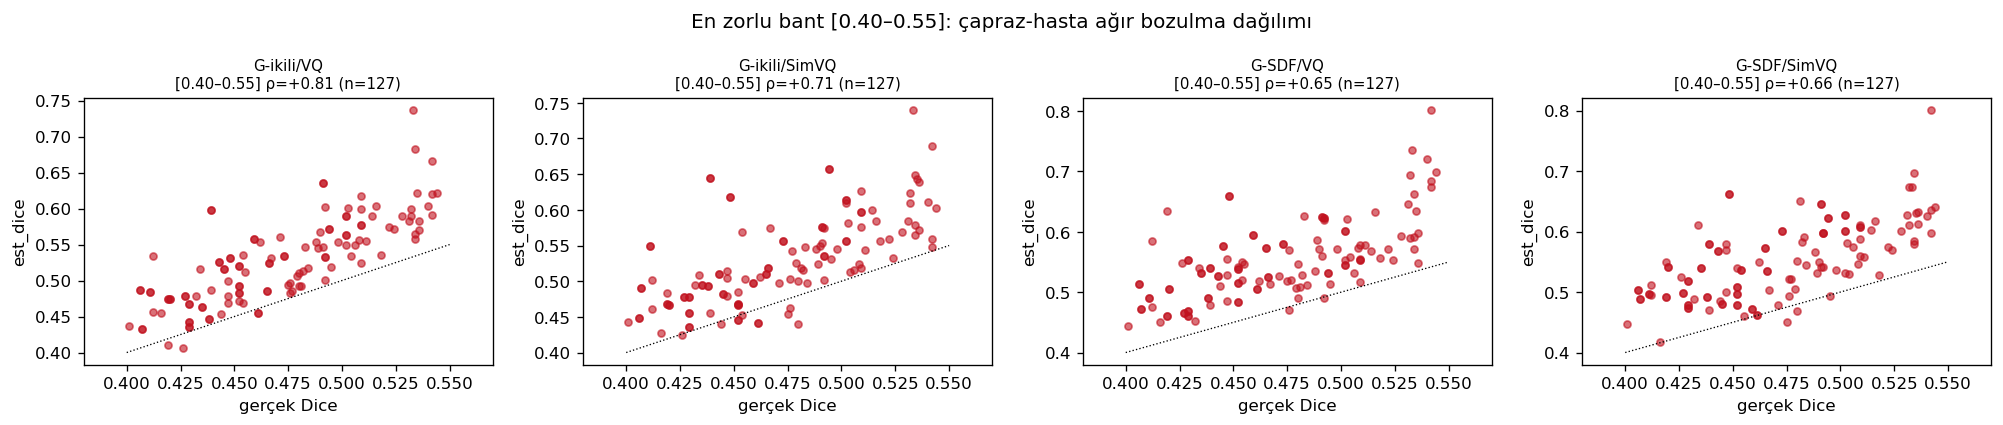

In [16]:
def heavy_probe_cross_patient(lbl, band=(0.40, 0.55)):
    model = fpfn_results[lbl]['model']
    rows = []
    # Agir primitiflerin Dice yaniti diktir; bandi doldurmak icin her hasta x her primitif x
    # bir kac siddet taranir, gercek Dice bandina dusenler tutulur. Tum hastalardan toplanir
    # (hastalar-arasi siralama = durust sayi).
    sweeps = {'center_only': np.linspace(0.40, 0.60, 5),
              'heavy_erode': np.linspace(0.14, 0.24, 5),
              'erode': np.linspace(0.45, 0.80, 6)}
    for pid, (gt_, img_) in enumerate(zip(clean_masks, clean_images)):
        gt_ = gt_.astype(bool)
        for name, sevs in sweeps.items():
            for sev in sevs:
                b = np.asarray(ALL_FNS[name](gt_, float(sev), np.random.default_rng(SEED + pid))) > 0
                if not (0 < int(b.sum()) < gt_.size):
                    continue
                d_true = float(_dc(gt_, b))
                if not (band[0] <= d_true <= band[1]):
                    continue
                x = torch.from_numpy(np.stack([img_, b.astype('float32')])[None]).float().to(device)
                with torch.no_grad():
                    fp, fn = model.predict_fpfn(x)
                    ed = float(estimated_dice(x[:, 1:2], fp, fn)[0])
                    ev = float(error_volume(fp, fn)[0])
                rows.append(dict(hasta=pid, primitif=name, sev=round(float(sev), 2),
                                 gerçek_Dice=round(d_true, 3), est_dice=round(ed, 3),
                                 error_volume=int(ev)))
    return rows

labels = [l for l, *_ in FPFN_REGISTRY if l in fpfn_results]
probe_all = {}
for lbl in labels:
    rows = heavy_probe_cross_patient(lbl)
    probe_all[lbl] = rows
    if len(rows) >= 3:
        td = np.array([r['gerçek_Dice'] for r in rows])
        es = np.array([r['est_dice'] for r in rows])
        rho = correlation(es, td)['spearman']
        print(f'{lbl:16s} [0.40–0.55] çapraz-hasta (ağır bozulma, n={len(rows)}): '
              f'est_dice ρ = {rho:+.3f}')
    else:
        print(f'{lbl:16s} bandına düşen ağır örnek az (n={len(rows)})')

# en zorlu banttaki dağılım: est_dice vs gerçek Dice (çapraz-hasta)
if labels:
    fig, axes = plt.subplots(1, len(labels), figsize=(4.2 * len(labels), 3.6), squeeze=False)
    for ax, lbl in zip(axes[0], labels):
        rows = probe_all[lbl]
        if not rows:
            ax.axis('off'); continue
        td = np.array([r['gerçek_Dice'] for r in rows]); es = np.array([r['est_dice'] for r in rows])
        rho = correlation(es, td)['spearman']
        ax.scatter(td, es, s=18, alpha=0.6, c='#c1121f')
        ax.plot([0.40, 0.55], [0.40, 0.55], 'k:', lw=0.8)
        ax.set_xlim(0.38, 0.57); ax.set_title(f'{lbl}\n[0.40–0.55] ρ={rho:+.2f} (n={len(rows)})', fontsize=9)
        ax.set_xlabel('gerçek Dice'); ax.set_ylabel('est_dice')
    fig.suptitle('En zorlu bant [0.40–0.55]: çapraz-hasta ağır bozulma dağılımı', fontsize=12)
    fig.tight_layout()
    out = PROJECT_ROOT / 'outputs' / 'rapor_fpfn_agir_bant_scatter.png'
    fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_agir_bozulma.png


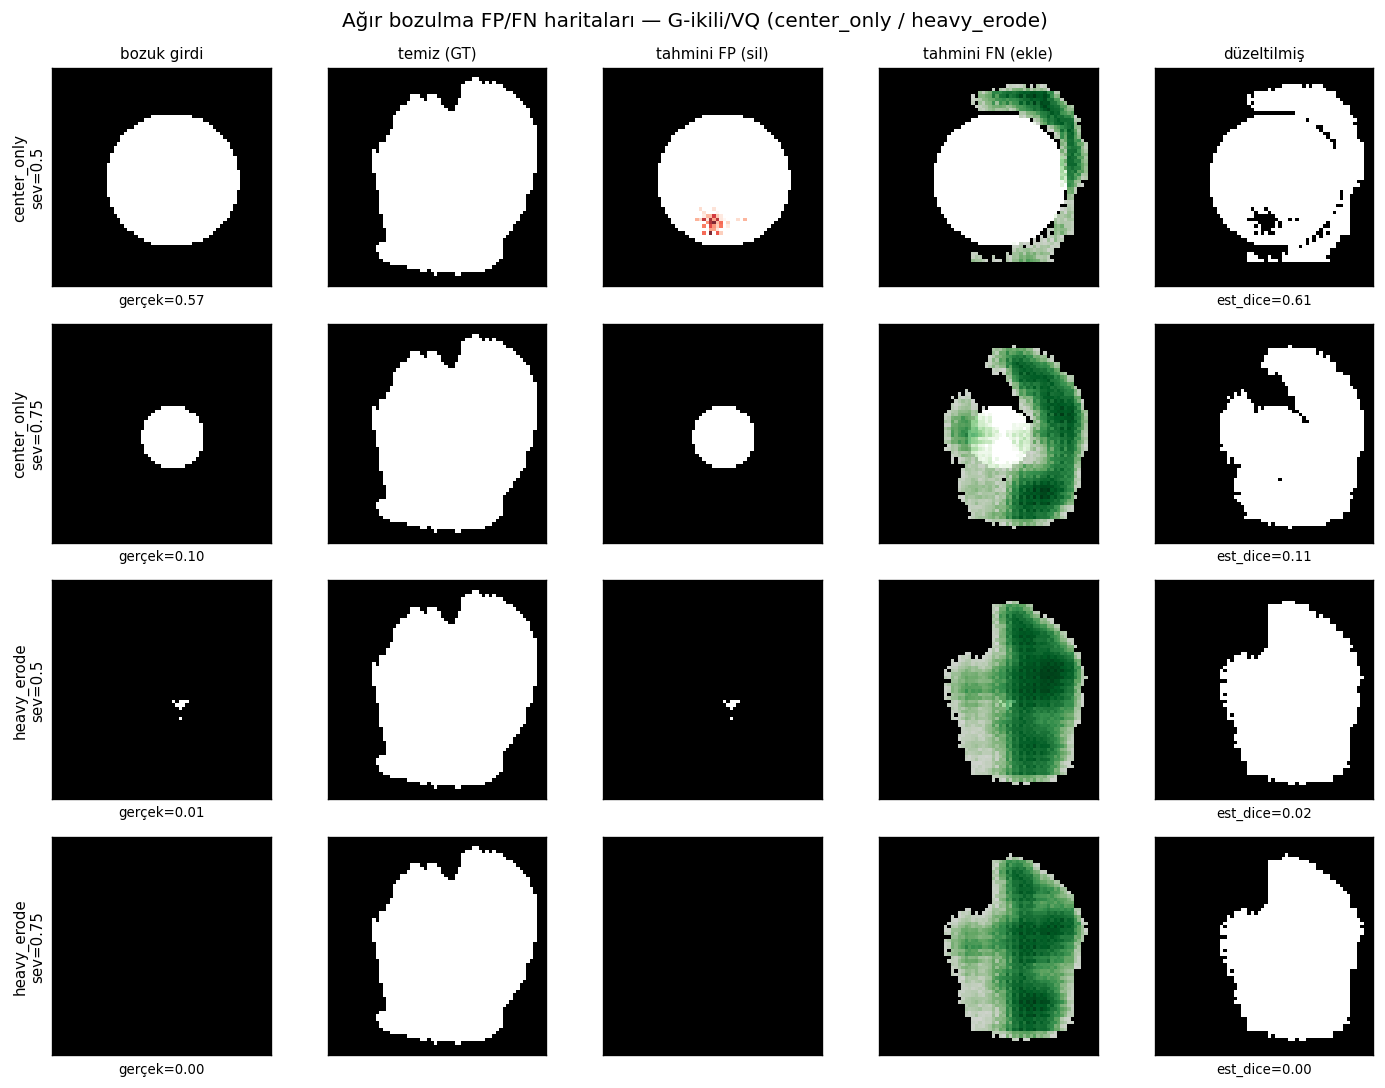

In [17]:
# Ağır bozulmaların FP/FN haritaları (ilk mevcut varyantta) — center_only ve heavy_erode
if labels:
    lbl = labels[0]; model = fpfn_results[lbl]['model']
    gt = clean_masks[PANEL_IDX].astype(bool); img = clean_images[PANEL_IDX]
    heavy_specs = [('center_only', 0.5), ('center_only', 0.75), ('heavy_erode', 0.5), ('heavy_erode', 0.75)]
    fig, axes = plt.subplots(len(heavy_specs), 5, figsize=(12, 2.3 * len(heavy_specs)))
    cols = ['bozuk girdi', 'temiz (GT)', 'tahmini FP (sil)', 'tahmini FN (ekle)', 'düzeltilmiş']
    for ri, (name, sev) in enumerate(heavy_specs):
        b = np.asarray(ALL_FNS[name](gt, sev, np.random.default_rng(SEED))) > 0
        d_true = float(_dc(gt, b))
        fp, fn, comp = predict_maps(model, img, b)
        ed = float(estimated_dice(torch.from_numpy(b[None, None].astype('float32')),
                                  torch.from_numpy((fp > 0.5)[None, None].astype('float32')),
                                  torch.from_numpy((fn > 0.5)[None, None].astype('float32')))[0])
        axes[ri, 0].imshow(b[zc], cmap='gray')
        axes[ri, 1].imshow(gt[zc], cmap='gray')
        axes[ri, 2].imshow(b[zc], cmap='gray')
        axes[ri, 2].imshow(np.ma.masked_where(fp[zc] <= 0.5, fp[zc]), cmap='Reds', alpha=0.85)
        axes[ri, 3].imshow(b[zc], cmap='gray')
        axes[ri, 3].imshow(np.ma.masked_where(fn[zc] <= 0.5, fn[zc]), cmap='Greens', alpha=0.85)
        axes[ri, 4].imshow(comp[zc], cmap='gray')
        for ci in range(5):
            axes[ri, ci].set_xticks([]); axes[ri, ci].set_yticks([])
            if ri == 0: axes[ri, ci].set_title(cols[ci], fontsize=9)
        axes[ri, 0].set_ylabel(f'{name}\nsev={sev}', fontsize=9)
        axes[ri, 0].set_xlabel(f'gerçek={d_true:.2f}', fontsize=8)
        axes[ri, 4].set_xlabel(f'est_dice={ed:.2f}', fontsize=8)
    fig.suptitle(f'Ağır bozulma FP/FN haritaları — {lbl} (center_only / heavy_erode)', fontsize=12)
    fig.tight_layout()
    out = PROJECT_ROOT / 'outputs' / 'rapor_fpfn_agir_bozulma.png'
    fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## 13. (İkincil) Okey/riskli eşik analizi ve AUROC — hastane triyaj bakışı

> Bu bölüm **ikincil**dir; defterin ana konusu `est_dice`'ın gerçek Dice ile korelasyonudur
> (Bölüm 6–10). Burada aynı skor, hastanedeki pratik bir **karar** sorusuna uyarlanır: *"bu maske
> okey mi, yoksa bir uzman mutlaka baksın mı (riskli mi)?"*

Senaryo: model `[BT, maske]` alır, GT-free `est_dice` üretir; bir **eşik** altındaki maskeler
**riskli** (insan kontrolüne öncelik), üstündekiler **okey** sayılır. "Gerçekte riskli" etiketini
doğrulama için GT'den tanımlarız: gerçek Dice < `DICE_ESIK`. AUROC, `est_dice`'ın eşikten bağımsız
olarak riskli/okey maskeleri **ayırma** gücünü (1.0 = kusursuz, 0.5 = rastgele) ölçer. Altında seçilen
bir çalışma eşiği için duyarlılık (riskli maskeleri yakalama oranı) ve özgüllük raporlanır.

In [18]:
DICE_ESIK = 0.80     # gerçekte 'riskli' tanımı: gerçek Dice < 0.80
EST_ESIK  = 0.80     # calisma esigi: est_dice < 0.80 -> 'riskli' uyarisi

def auroc_manual(score_good, y_good):
    # y_good: 1 = okey (pozitif, yuksek skor beklenir), 0 = riskli. Rank-temelli AUC.
    order = np.argsort(score_good)
    ranks = np.empty(len(score_good), float); ranks[order] = np.arange(1, len(score_good) + 1)
    n_pos = int(y_good.sum()); n_neg = int(len(y_good) - n_pos)
    if n_pos == 0 or n_neg == 0:
        return float('nan')
    return (ranks[y_good == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

labels = [l for l, *_ in FPFN_REGISTRY if l in fpfn_results]
auroc_rows = []
for lbl in labels:
    est = fpfn_results[lbl]['scores']['est_dice']
    okey_true = (true_dice >= DICE_ESIK).astype(int)     # 1 = okey, 0 = riskli
    try:
        from sklearn.metrics import roc_auc_score
        au = float(roc_auc_score(okey_true, est))
    except Exception:
        au = auroc_manual(est, okey_true)
    pred_riskli = est < EST_ESIK
    true_riskli = true_dice < DICE_ESIK
    tp = int((pred_riskli & true_riskli).sum())      # riskliyi riskli dedi
    fn_ = int((~pred_riskli & true_riskli).sum())    # riskliyi kacirdi (okey dedi)
    fp_ = int((pred_riskli & ~true_riskli).sum())    # okeyi bosuna riskli dedi
    tn = int((~pred_riskli & ~true_riskli).sum())
    sens = tp / (tp + fn_) if (tp + fn_) else float('nan')   # riskli yakalama
    spec = tn / (tn + fp_) if (tn + fp_) else float('nan')   # okey birakma
    auroc_rows.append({'model': lbl, 'AUROC': round(au, 3),
                       'riskli yakalama (duyarlılık)': round(sens, 3),
                       'okey özgüllük': round(spec, 3),
                       'riskli→riskli (TP)': tp, 'riskli→okey (kaçan, FN)': fn_,
                       'okey→riskli (gereksiz, FP)': fp_, 'okey→okey (TN)': tn})

print(f'etiket: gerçek Dice < {DICE_ESIK} => RİSKLİ | çalışma eşiği: est_dice < {EST_ESIK}')
try:
    import pandas as pd
    auroc_df = pd.DataFrame(auroc_rows)
    display(auroc_df)
except Exception:
    for row in auroc_rows: print(row)

etiket: gerçek Dice < 0.8 => RİSKLİ | çalışma eşiği: est_dice < 0.8


,model,AUROC,riskli yakalama (duyarlılık),okey özgüllük,riskli→riskli (TP),"riskli→okey (kaçan, FN)","okey→riskli (gereksiz, FP)",okey→okey (TN)
0,G-ikili/VQ,0.985,0.662,1.0,106,54,0,122
1,G-ikili/SimVQ,0.988,0.694,1.0,111,49,0,122
2,G-SDF/VQ,0.971,0.537,1.0,86,74,0,122
3,G-SDF/SimVQ,0.985,0.606,1.0,97,63,0,122


kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_fpfn_auroc_triyaj.png


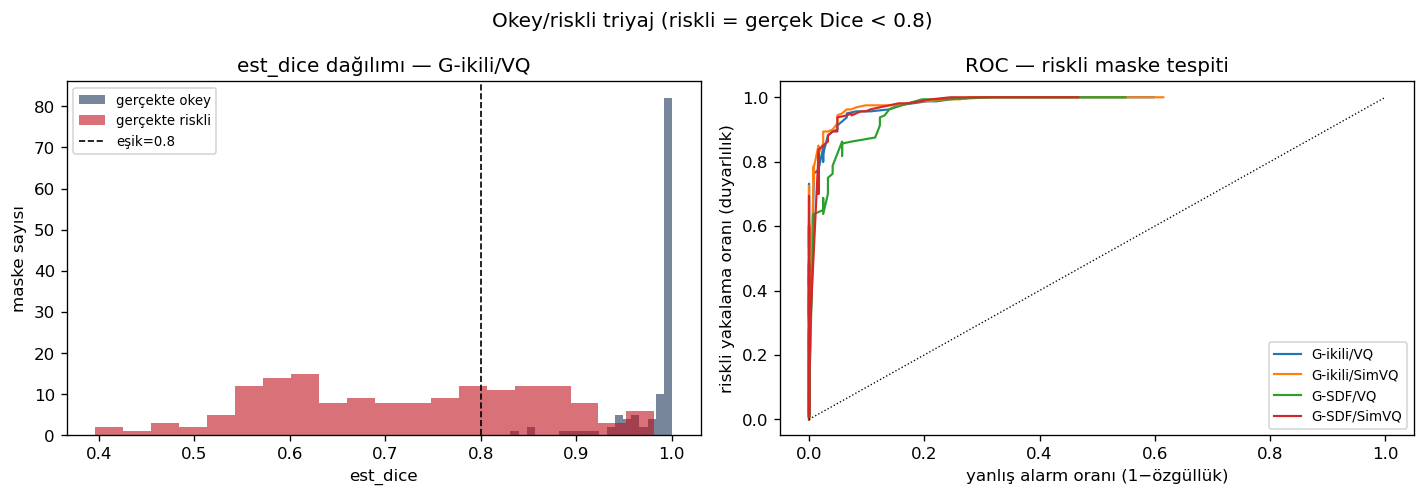

In [19]:
# est_dice dagilimi: okey (gercek Dice>=esik) vs riskli maskeler ic ice histogram + ROC
labels = [l for l, *_ in FPFN_REGISTRY if l in fpfn_results]
if labels:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    lbl0 = labels[0]
    est0 = fpfn_results[lbl0]['scores']['est_dice']
    riskli = true_dice < DICE_ESIK
    axes[0].hist(est0[~riskli], bins=20, alpha=0.6, color='#1d3557', label='gerçekte okey')
    axes[0].hist(est0[riskli], bins=20, alpha=0.6, color='#c1121f', label='gerçekte riskli')
    axes[0].axvline(EST_ESIK, color='k', ls='--', lw=1, label=f'eşik={EST_ESIK}')
    axes[0].set_xlabel('est_dice'); axes[0].set_ylabel('maske sayısı')
    axes[0].set_title(f'est_dice dağılımı — {lbl0}'); axes[0].legend(fontsize=8)
    # ROC egrileri (tum modeller)
    for lbl in labels:
        est = fpfn_results[lbl]['scores']['est_dice']
        okey_true = (true_dice >= DICE_ESIK).astype(int)
        thrs = np.linspace(est.min(), est.max(), 100)
        tpr, fpr = [], []
        pos = okey_true == 0  # riskli = pozitif sinif (yakalamak istedigimiz)
        for t in thrs:
            pred = est < t
            tp = (pred & pos).sum(); fn_ = (~pred & pos).sum()
            fp_ = (pred & ~pos).sum(); tn = (~pred & ~pos).sum()
            tpr.append(tp / (tp + fn_) if (tp + fn_) else 0)
            fpr.append(fp_ / (fp_ + tn) if (fp_ + tn) else 0)
        order = np.argsort(fpr)
        axes[1].plot(np.array(fpr)[order], np.array(tpr)[order], lw=1.3, label=lbl)
    axes[1].plot([0, 1], [0, 1], 'k:', lw=0.8)
    axes[1].set_xlabel('yanlış alarm oranı (1−özgüllük)')
    axes[1].set_ylabel('riskli yakalama oranı (duyarlılık)')
    axes[1].set_title('ROC — riskli maske tespiti'); axes[1].legend(fontsize=8, loc='lower right')
    fig.suptitle(f'Okey/riskli triyaj (riskli = gerçek Dice < {DICE_ESIK})', fontsize=12)
    fig.tight_layout()
    out = PROJECT_ROOT / 'outputs' / 'rapor_fpfn_auroc_triyaj.png'
    fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## 14. Checkpoint yolundan canlı tek-hasta çıkarımı

Herhangi bir eğitilmiş FP/FN modeli, yolu verilerek yeniden yüklenip tek bir test hastası üzerinde
çalıştırılabilir. `CKPT_PATH` / `HEAD` / `QUANT` / `PATIENT_IDX` / `TARGET_DICE` değiştirilerek herhangi
bir model/hasta/bozulma seviyesi denenebilir. Hücre modeli yükler, girdiyi bozar, FP/FN tahmin eder,
düzeltmeyi üretir ve est_dice ile gerçek Dice'ı karşılaştırır.

girdi Dice = 0.621  ->  düzeltilmiş Dice = 0.796  |  est_dice (GT-free) = 0.685


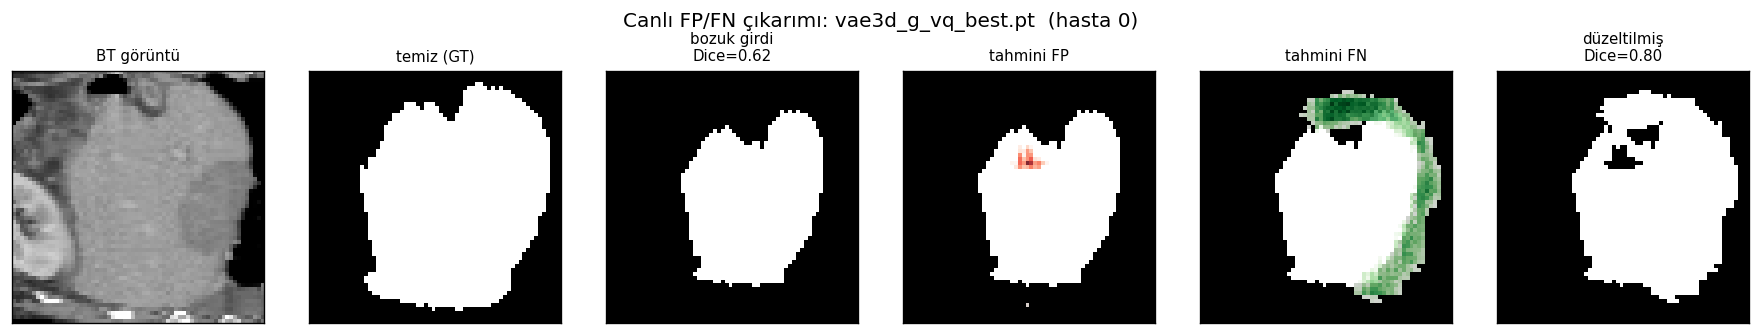

In [20]:
CKPT_PATH = CKPT / 'vae3d_g_vq_best.pt'   # değiştirilebilir
HEAD, QUANT = 'binary', 'vq'              # yukarıdaki checkpoint'e uygun olmalı
PATIENT_IDX = 0
TARGET_DICE = 0.6

live_model = evfpfn.load_fpfn_model(CKPT_PATH, HEAD, QUANT, device)
gt = clean_masks[PATIENT_IDX].astype(bool)
img = clean_images[PATIENT_IDX]
rng_live = np.random.default_rng(SEED)
brk, d_in = degrader.make_pair(gt, rng_live, target_dice=TARGET_DICE)
brk = np.asarray(brk) > 0
fp, fn, comp = predict_maps(live_model, img, brk)
d_comp = float(_dc(gt, comp))
x_live = torch.from_numpy(np.stack([img, brk.astype('float32')])[None]).float().to(device)
with torch.no_grad():
    _fp, _fn = live_model.predict_fpfn(x_live)
    ed = float(estimated_dice(x_live[:, 1:2], _fp, _fn)[0])

zc = gt.shape[0] // 2
titles = ['BT görüntü', 'temiz (GT)', f'bozuk girdi\nDice={d_in:.2f}',
          'tahmini FP', 'tahmini FN', f'düzeltilmiş\nDice={d_comp:.2f}']
fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
axes[0].imshow(img[zc], cmap='gray')
axes[1].imshow(gt[zc], cmap='gray')
axes[2].imshow(brk[zc], cmap='gray')
axes[3].imshow(brk[zc], cmap='gray'); axes[3].imshow(np.ma.masked_where(fp[zc] <= 0.5, fp[zc]), cmap='Reds', alpha=0.85)
axes[4].imshow(brk[zc], cmap='gray'); axes[4].imshow(np.ma.masked_where(fn[zc] <= 0.5, fn[zc]), cmap='Greens', alpha=0.85)
axes[5].imshow(comp[zc], cmap='gray')
for ax, t in zip(axes, titles):
    ax.set_title(t, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f'Canlı FP/FN çıkarımı: {CKPT_PATH.name}  (hasta {PATIENT_IDX})', fontsize=12)
fig.tight_layout(); plt.show()
print(f'girdi Dice = {d_in:.3f}  ->  düzeltilmiş Dice = {d_comp:.3f}  |  est_dice (GT-free) = {ed:.3f}')

## 15. Bulguların özeti

- **FP/FN formülasyonu maske kullanımını zorlar.** Hedefler girdi maskesine göreli tanımlandığından
  model maskeyi yok sayarak "ne silineceğini / ne ekleneceğini" söyleyemez; `est_dice`'ın yüksek
  korelasyonu (g_vq: ρ ≈ 0.948) maskenin gerçekten kullanıldığının doğrudan kanıtıdır (maskeyi yok
  sayan bir model girdi-keyed FP/FN üretemeyeceğinden ρ ≈ 0 verirdi). Bu, tamamlama hattındaki
  confound'u kapatır.

- **ASSD sayısal kenar-hatası iyileşmesi.** Düzeltilmiş maske sınırı gerçek yüzeye yaklaştırır;
  g_vq'da ortalama ASSD bozuk satırlarda 3.24 → 1.87 (~%42 azalma). Bu, FP/FN'nin yalnızca hacim
  değil **sınır** hatalarını da düzelttiğini gösterir.

- **Dürüst çekince — bant-içi ρ global'den düşüktür ve bozulma türüne bağlıdır.** Global ρ
  hastalar-arası varyansla şişkindir; bant-içi ρ dürüst sayıdır. g_vq'da **eval kümesinin** en düşük
  bandı [0.40–0.55] (standart primitif karışımı) est_dice ρ ≈ 0.18 ile zayıftır — bu bantta karışık
  bozulma türleri arasında ince sıralama zordur. Orta-üst bantlarda (0.55–0.85) ρ ≈ 0.60–0.79 ile
  daha güçlüdür. Buna karşılık Bölüm 12'deki **ağır yapısal** bozulmalar (center_only / heavy_erode /
  erode) aynı [0.40–0.55] bandında hastalar-arası est_dice ρ ≈ 0.81 verir: yani düşük-bant zayıflığı
  bozulma türü karışımından kaynaklanır, "ağır eksik maskeleri sıralayamama"dan değil. İki sayı
  birlikte okunmalıdır; tek bir bant-içi ρ'yu yöntemin tümüne genellemek yanıltıcı olur.

- **Hata-türü × model tablosu (Bölüm 9).** Tek geniş tablo her bozulma türünde her modelin Dice ve
  ASSD başarımını (girdi → düzeltilmiş) ve `est_dice`'ın tür-içi Pearson/Spearman değerini yan yana
  verir. Türler arası fark gerçektir: hacimsel/sınır hatası türlerinde (erode, dilate, translate)
  düzeltme ve korelasyon genelde güçlü; ağır yapısal eksilme türlerinde (center_only) daha değişkendir.
  Sonuç metinden değil **doğrudan tablodan** okunmalıdır.

- **Triyaj (ikincil, Bölüm 13).** Aynı `est_dice`, bir eşikle "okey/riskli" kararına çevrildiğinde
  riskli maskeleri ayırmada AUROC ile ölçülebilir bir güç gösterir; bu, hastanede en kötü maskeleri
  insan kontrolüne önceliklendirmek için pratik bir kullanım sunar. Ana bulgu yine korelasyondur;
  triyaj bunun bir uygulamasıdır.

- **Varyantlar.** İkili vs SDF başı ve VQ vs SimVQ arasındaki fark ikincil beklenir; belirleyici olan
  FP/FN formülasyonunun kendisidir. (Bu defter mevcut checkpoint'leri canlı skorlar; eksik varyantlar
  eğitildikçe tablolar otomatik dolar — sonuçlar metin yerine tablodan okunmalıdır.)